<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QBagging_AdversarialRobustness_Wiebe2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum bagging and private clustering for hardened QML: Wiebe and Kumar (2017) step by step

This notebook re-implements and numerically checks the claims of

> Nathan Wiebe and Ram Shankar Siva Kumar, "Hardening Quantum Machine Learning Against Adversaries",
> New Journal of Physics 20, 123019 (2018); arXiv:1711.06652 [quant-ph], 17 November 2017.
> https://arxiv.org/abs/1711.06652

**This is a theory paper.** It has no experiment, no dataset, no table of measured accuracies and no figure with numbers.
Its results are definitions, lemmas, theorems and one corollary about (i) *robust quantum PCA* (Section III),
(ii) *quantum bootstrap aggregation / boosting* of classifiers (Section IV) and (iii) a *private quantum k-means* protocol
(Section V). A notebook can therefore not "reproduce a number"; what it can do is **check every statement that is
checkable by computation**, on real data, against real attacks, and say plainly which statements cannot be checked.

**What the notebook does.**
1. Downloads the public **Spambase** e-mail data set (UCI; 4,601 e-mails, spam vs. not spam; the paper's own motivating
   example is spam filtering) and reduces it to four angles, one per qubit, with transforms fitted on the training split only.
2. Checks the **robust-statistics machinery** of Section III numerically: the unit-vector embedding (Lemma 3), the
   median-stability bound (Lemma 4), the robust-PCA matrix bound of Theorem 5(2), and the effect of a poisoning attack on a
   PCA anomaly detector.
3. Builds the **quantum bagging classifier** of Section IV for real: many small variational classifiers
   (each one is a Hermitian, unitary observable C_j with eigenvalues +1 and -1) are trained on bootstrap samples; the
   ensemble C = sum_j b_j C_j is read out by **quantum phase estimation** exactly as in Definition 6 (a real Qiskit circuit);
   it is compared with the strawman "sign of the mean" (Eq. 8), with ordinary majority voting, and with classical
   baselines on the same inputs, under **real attacks**: training-label poisoning and an adversary that replaces a fraction
   alpha of the classifiers by the worst Hermitian unitary it can find (Threat Model 2). Eq. (10), the eigenvalue
   perturbation bound (A32) and Corollary 10 are checked on these attacks, and the Taylor-series cost of Lemma 8 is measured.
4. Simulates the **private k-means protocol** of Section V on real e-mails, checks Lemma 11 (it recovers the centroids with
   O(1/epsilon) rotations per participant) and Theorem 12 (the eavesdropper's best membership guess is 1/2 + O(q/N)) with a
   Qiskit circuit and a Monte-Carlo membership-inference attack, compares with a classical local-differential-privacy baseline,
   and tests the paper's remark that a malicious participant breaks the protocol unless a median over groups is used.
5. Ends with a verdict for each checkable claim, "Reading the paper critically", and exercises.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first code cell
installs a pinned Qiskit; if Colab asks to restart the session, restart and run all again. No GPU, no IBM account, no
Hugging Face token is needed (Spambase is public). The configuration cell as shipped has `FAST_MODE = False`, and **all
outputs in this notebook come from that full run** (24.5 minutes on a 4-core CPU: 31 members per bag, 600 training and 300 test
e-mails, 5 repetitions). Set `FAST_MODE = True` for the class demo (about 5 minutes: 15 members, 300 / 120 e-mails, 2
repetitions); its numbers differ slightly from the ones quoted below.

**What you get at the end.** A table "claim -> paper -> this notebook -> verdict", 17 figures (data views, four circuit
drawings, attack curves, privacy curves), and an honest list of what a classical simulator cannot say about quantum advantage.

**Results at a glance (full run).** Of the 20 verdict rows, 12 are *reproduced*, 6 are *not reached*, 1 *cannot be checked*
and 1 is our own check (it passed).
* *Reproduced:* Lemma 3, Lemma 4, Theorem 5 (2), Eq. (10) and (A32), Lemma 8, Lemma 11 (estimation error falls as
  1/rotations, log-log slope -0.99), Theorem 12 (exact circuit and a Monte-Carlo membership attack agree with
  1/2 + (1/2) sin(q/2N)), Definition 6 as a real phase-estimation circuit (99.7 % of decisions equal the ideal projector), the
  fragility of the sign-of-the-mean read-out (Eq. 8), the bootstrap's left-out fraction (36.8 % = 1/e), the median-over-groups
  repair of a malicious user, and (our own comparison, implied by the paper) the quantum protocol beats Laplace local
  differential privacy at equal membership advantage in 3 of 3 settings.
* *Not reached, and worth knowing:* **Corollary 10 does not hold as stated on this ensemble.** No eigenvalue changes sign while alpha < gamma/4 (1650
  of 1650 attacks), yet the class was flipped inside that radius for 149 of 150 attacked e-mails, because the eigenvectors rotate;
  a margin-aware certificate that we derive holds in all cases and covers at least one compromised member for 82 % of the
  e-mails. The eigenspace read-out needs the same number of compromised members as the sign of the mean (median 6 of 31), while
  a plain classical majority vote needs 16. Bagging does not raise accuracy (+0.9 points) and does not protect against label
  poisoning (spam recall falls by 66 points for both the single and the bagged VQC, by 35 for the SVCs). The Definition-1 robust
  PCA matrix is not a usable detector on spam features. The private k-means protocol needs at least 23,000 users for a 5 %
  membership advantage at the accuracy tested here; only 2,947 real e-mails are available.
* *Cannot be checked:* the oracle-model speedup claims (exponential for robust PCA, "quadratically easier" bagging).

## The paper in one page

**Problem.** Machine-learning systems used for spam filtering and intrusion detection are attacked by adversaries who
(a) poison the training data (*causative* attacks, e.g. the "wolf pack" attack on the Tay chat bot), (b) feed crafted inputs
to learn about the model or the training data (*exploratory* attacks), (c) compromise some of the models in an ensemble.
The paper asks whether quantum subroutines can help defend QML against these.

**Decision.** In every case the decision is binary: "is this vector normal or anomalous" (PCA), "is this test state in class
+1 or -1" (bagged classifier), or "did participant B contribute data" (privacy).

**Method (three proposals).**
* *Robust quantum PCA (Section III, Theorem 5).* Replace the mean in the covariance matrix by the **median**
  (Definition 1: M_kl = median([e_k.x_j - median(e_k.x_j)] [e_l.x_j - median(e_l.x_j)])). Lemma 4: if the data have a
  Lipschitz inverse CDF (constant L), an adversary who changes a fraction alpha < 1/2 of the data moves the median by at most
  alpha L. Theorem 5: query cost O(d^4/(Lambda^3 lambda^3) log^2(.)) and ||M - M'||_2 <= 5 alpha L (d + 2).
* *Quantum bagging / boosting (Section IV).* Ensemble observable C = sum_j b_j C_j with each C_j a +/-1-valued classifier.
  A test state is projected onto the eigenvectors of C by phase estimation; the class is +1 if the probability of landing in
  the positive eigenspace exceeds 1/2 (Definition 6). The sign of the *mean* <psi|C|psi> is explicitly rejected (Eq. 8):
  one compromised classifier can flip it. Lemma 8 / Theorem 9: queries O(t log(t/eps)/log log(t/eps)) and
  O((1/(delta eps)) log(1/eps)/log log(1/eps)). Corollary 10: if all |eigenvalues| >= gamma/2 and the adversary controls a
  fraction alpha < gamma/4 of the classifiers, the output class cannot change.
* *Private k-means (Section V).* N users share a GHZ-like state (|0>^N + |1>^N)/sqrt(2); user j applies a tiny rotation
  exp(-iZ/2N) (scaled by their cluster indicator or coordinate) and returns the qubit; the experimenter reads the *sum* of the
  phases by phase estimation. Lemma 11: centroids within error eps with O(d/(min_p P_p eps)) rotations per user.
  Theorem 12: the best possible membership guess succeeds with probability 1/2 + O(R d / (min P N eps)); N in Omega(R d k /(eps delta))
  suffices for advantage delta.

**Data.** None. The paper names no data set. (This notebook uses Spambase, see the table below.)

**Preprocessing.** None. (Training vectors are assumed to be unit vectors, Lemma 3 shows how to embed any bounded vector.)

**Claims (all analytic; none is a measured number).** Lemma 3, Lemma 4, Theorem 5 (1) and (2), Eq. (8), Lemma 8, Theorem 9,
Corollary 10, Eq. (10) and (A32), Lemma 11, Theorem 12, the closing remarks that a median over groups mitigates malicious
participants and that bagging "is quadratically easier" with quantum superposition, and the abstract's "exponential speedup"
for robust PCA. The speedup statements are statements about query complexity in an oracle model and **cannot be checked on a
classical simulator**; this notebook says so in the verdict table instead of inventing a number.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | none | Spambase (UCI id 94): 4,601 e-mails, 57 features, spam / not spam; the paper's motivating example is spam filtering. After removing exact duplicates: see output |
| Features -> qubits | training vectors as unit vectors / quantum states | `log1p` -> `StandardScaler` -> `PCA(4)` -> `MinMaxScaler((0, pi))`, all fitted on the training split only; one angle per qubit |
| State preparation | oracle `U_QRAM` | product state RY(x_1) x ... x RY(x_4) on 4 qubits (a real Qiskit circuit) |
| Member classifier C_j | any unitary with eigenvalues +/-1 | C_j = V_j^T Z_0 V_j: `real_amplitudes(4, reps=2, entanglement="full")` followed by a Z measurement on qubit 0 (12 trainable angles) |
| Training of members | "training on subsets of the data" | squared loss between <Z_0> and the label (+1 spam, -1 not spam), COBYLA, bootstrap sample (with replacement) per member |
| Weights b_j | b_j >= 0, sum 1 | uniform b_j = 1/M |
| Aggregation | phase estimation of e^{-iC} | exact Qiskit circuit with `m` evaluation qubits and U = exp(-i (pi/2) C); sign read from the top evaluation bit |
| Adversary of Threat Model 2 | unbounded, knows everything | replaces a members of the ensemble by a Hermitian unitary found by reflection and by a hill-climbing search; also the strongest possible hard-vote attack for majority voting |
| Median-statistics Lipschitz constant L | assumed finite | estimated from the data as the largest secant slope of the empirical quantile function on [1/2 - alpha, 1/2 + alpha] (the only range the proof of Lemma 4 uses) |
| Private k-means data | N users with vectors | the Spambase e-mails of the training pool: the same four principal components, clipped at +/-2 standard deviations and mapped to [0, 1]^4; k = 2 clusters; GHZ phases simulated exactly |
| Phase estimation inside Lemma 11 | "well understood" | rotation counts t = 1, 2, 4, ..., both quadratures measured, `s` shots each, grid maximum-likelihood estimate |
| Classical baselines | none | SVC(rbf), RandomForest, bagged SVC on the same four angles; classical majority vote of the same member classifiers; Laplace local-DP k-means for the privacy section |
| Seeds | none | `SEED = 42` everywhere |

Every row marked "CHOICE" in the code comments corresponds to a line of this table.

## 0. Setup

The first cell installs a pinned Qiskit (Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib). Nothing else is
needed: the quantum parts are exact statevector simulations written with Qiskit's circuit objects, and every faster
vectorised helper is asserted equal to the Qiskit circuit it replaces.

In [1]:
# Versions tested with this notebook (October 2026). The pip line runs on Colab (or wherever qiskit is missing);
# a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("pylatexenc") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc ucimlrepo
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit already present; skipping pip install.")

qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: class demo (about 5 min on an idle 4-core CPU). False: the larger budgets below (about 1 h).
SEED      = 42              # CHOICE: the paper gives no seed
N_QUBITS  = 4               # one angle per qubit; the ensemble observable C acts on 2**4 = 16 dimensions
ANSATZ_REPS = 2             # CHOICE: real_amplitudes(4, reps=2): 12 trainable angles per member
TEST_POOL_FRACTION = 0.3    # share of the cleaned data kept aside as the test pool

if FAST_MODE:
    N_TRAIN, N_TEST = 300, 120      # balanced samples (half spam, half not spam)
    N_MEMBERS   = 15                # M: classifiers in the quantum bag
    MAXITER     = 150               # COBYLA iterations per member
    N_REPEATS   = 2                 # independent repetitions (different seeds) for accuracy tables
    N_ATTACK_STATES = 50            # test states attacked in Threat Model 2
    ATTACK_STEPS    = 40            # hill-climbing steps of the strongest attack found
    QPE_POINTS  = 4                 # test states run through the full Qiskit phase-estimation circuit
    QPE_BITS    = 6                 # evaluation qubits m of the phase estimation
    PE_TRIALS   = 60                # repetitions per row of the phase-estimation study (Lemma 11)
    PE_SHOTS    = 10                # shots per quadrature and per t
    MC_TRIALS   = 20000             # Monte-Carlo trials of the membership-inference attack
    LEMMA4_ALPHAS = [0.05, 0.10, 0.20, 0.30, 0.40]
    POISON_FRACTIONS = [0.0, 0.4]
    DET_ALPHAS  = [0.0, 0.1, 0.3]   # poisoning fractions of the PCA detector study
else:
    N_TRAIN, N_TEST = 600, 300
    N_MEMBERS   = 31
    MAXITER     = 300
    N_REPEATS   = 5
    N_ATTACK_STATES = 150
    ATTACK_STEPS    = 120
    QPE_POINTS  = 12
    QPE_BITS    = 6
    PE_TRIALS   = 300
    PE_SHOTS    = 20
    MC_TRIALS   = 200000
    LEMMA4_ALPHAS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]
    POISON_FRACTIONS = [0.0, 0.2, 0.4]
    DET_ALPHAS  = [0.0, 0.05, 0.1, 0.2, 0.3]

K_CLUSTERS    = 2           # clusters of the private k-means
KMEANS_ROUNDS = 3           # R rounds of the protocol
TAU           = 1.5707963267948966   # = pi/2: evolution time of U = exp(-i TAU C); eigenphase -E/4 keeps the sign of E in the top qubit
DATA_DIR  = "data"          # cache for the downloaded Spambase files (relative to the working directory)
IBM_TOKEN = ""              # not used: every circuit here is simulated exactly; no real-hardware cell exists
print("FAST_MODE =", FAST_MODE, "| members M =", N_MEMBERS, "| train/test =", N_TRAIN, "/", N_TEST)

FAST_MODE = False | members M = 31 | train/test = 600 / 300


In [3]:
import os, io, re, time, math, warnings, itertools
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import scipy, sklearn
from scipy.optimize import minimize
from scipy.linalg import expm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes, UnitaryGate, QFTGate
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
COL = {0: "#1f77b4", 1: "#d62728"}      # not spam = blue, spam = red
NAME = {0: "not spam", 1: "spam"}
print("qiskit", qiskit.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

qiskit 2.5.2 | numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1


## 1. The Spambase data set

The paper names no data. Its opening paragraphs motivate every attack with **spam filtering** ("junk emails are classified as
normal") and intrusion detection. We therefore use **Spambase** (Hopkins, Reeber, Forman and Suermondt, Hewlett-Packard Labs,
1999; UCI Machine Learning Repository, id 94): 4,601 real e-mails, 1,813 of them spam, described by 57 numeric features
(48 word frequencies, 6 character frequencies, 3 statistics of runs of capital letters). It is public and licence-free for
research, so the notebook downloads it itself and caches it in `DATA_DIR`.

Cleaning follows the repository convention: coerce to numeric, remove +/-inf and NaN rows, drop exact duplicate rows, drop
constant columns. The label is 1 for spam and 0 for not spam.

In [4]:
UCI_BASE = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/"

def load_spambase():
    data_p, names_p = os.path.join(DATA_DIR, "spambase.data"), os.path.join(DATA_DIR, "spambase.names")
    try:
        for fn, p in (("spambase.data", data_p), ("spambase.names", names_p)):
            if not os.path.exists(p):
                r = requests.get(UCI_BASE + fn, timeout=60); r.raise_for_status()
                open(p, "wb").write(r.content)
        names = re.findall(r"^(\S+):\s+continuous\.", open(names_p, encoding="latin-1").read(), flags=re.M)
        raw = pd.read_csv(data_p, header=None)
        print("loaded from the UCI archive (cached in %s)" % DATA_DIR)
    except Exception as e:                       # fallback: the ucimlrepo client
        print("direct download failed (%s); trying ucimlrepo" % type(e).__name__)
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=94)
        names = list(ds.data.features.columns)
        raw = pd.concat([ds.data.features, ds.data.targets], axis=1); raw.columns = range(raw.shape[1])
    assert len(names) == 57 and raw.shape[1] == 58, (len(names), raw.shape)
    raw.columns = names + ["is_spam"]
    return raw

raw = load_spambase()
df = raw.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
n_dup = int(df.duplicated().sum()); df = df.drop_duplicates().reset_index(drop=True)
feature_names = [c for c in df.columns if c != "is_spam"]
const = [c for c in feature_names if df[c].nunique() <= 1]
df = df.drop(columns=const); feature_names = [c for c in feature_names if c not in const]
df["is_spam"] = df["is_spam"].astype(int)
print(f"raw rows: {len(raw)} | exact duplicates removed: {n_dup} | constant columns removed: {const} | cleaned shape: {df.shape}")
print("class counts (cleaned):", df["is_spam"].map(NAME).value_counts().to_dict(), "  (UCI documentation: 1,813 spam, 2,788 not spam before de-duplication)")
df.head(3)

loaded from the UCI archive (cached in data)


raw rows: 4601 | exact duplicates removed: 391 | constant columns removed: [] | cleaned shape: (4210, 58)
class counts (cleaned): {'not spam': 2531, 'spam': 1679}   (UCI documentation: 1,813 spam, 2,788 not spam before de-duplication)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,...,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,...,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,...,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,...,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1


## 2. Split and train-only preprocessing

The cleaned e-mails are split, stratified, into a **training pool** (70 %) and a **test pool** (30 %). The quantum models are
simulated exactly on 16-dimensional state vectors, so we draw class-balanced samples of `N_TRAIN` and `N_TEST` e-mails from the
two pools (half spam, half not spam; `random_state = SEED`). Every fitted transform sees the training sample only:

`log1p` (word frequencies are very skewed; CHOICE) -> `StandardScaler` -> `PCA(4)` -> `MinMaxScaler((0, pi))`.

Test angles are clipped to [0, pi]. Four principal components give one angle per qubit. The only hyper-parameters (ansatz depth,
iteration budget) are fixed in advance and are not tuned on the test data, so no validation split is needed.

In [5]:
X_all = np.log1p(df[feature_names].values.astype(float))     # CHOICE: log1p of the skewed frequencies
y_all = df["is_spam"].values
pool_tr, pool_te = train_test_split(np.arange(len(df)), test_size=TEST_POOL_FRACTION, stratify=y_all, random_state=SEED)

def balanced_pick(idx, n, seed):
    """# CHOICE: n/2 spam + n/2 not-spam rows drawn at random (without replacement) from a pool of row indices."""
    r = np.random.default_rng(seed)
    lab = y_all[idx]
    pick = np.concatenate([r.choice(idx[lab == 0], n // 2, replace=False), r.choice(idx[lab == 1], n - n // 2, replace=False)])
    return r.permutation(pick)

tr_idx = balanced_pick(pool_tr, N_TRAIN, SEED)
te_idx = balanced_pick(pool_te, N_TEST, SEED + 1)
assert len(set(tr_idx) & set(te_idx)) == 0

scaler = StandardScaler().fit(X_all[tr_idx])                        # fitted on the training sample only
pca    = PCA(n_components=N_QUBITS, random_state=SEED).fit(scaler.transform(X_all[tr_idx]))
Z_tr, Z_te = (pca.transform(scaler.transform(X_all[i])) for i in (tr_idx, te_idx))
minmax = MinMaxScaler((0, np.pi)).fit(Z_tr)
A_tr = minmax.transform(Z_tr)
A_te = np.clip(minmax.transform(Z_te), 0, np.pi)                    # test angles clipped to [0, pi]
y_tr, y_te = y_all[tr_idx], y_all[te_idx]
print("training sample:", A_tr.shape, np.bincount(y_tr), "| test sample:", A_te.shape, np.bincount(y_te))
print("PCA explained variance ratio:", np.round(pca.explained_variance_ratio_, 3), "(sum %.3f)" % pca.explained_variance_ratio_.sum())

training sample: (600, 4) [300 300] | test sample: (300, 4) [150 150]
PCA explained variance ratio: [0.127 0.084 0.04  0.034] (sum 0.285)


## Dataset Exploration and Visualisation

Everything below uses the real Spambase e-mails and their ground-truth labels (spam / not spam). The data set has only two
classes, so there are no attack families to colour by. First the shape, the feature names and the original label values, then
the class distribution, then two scatter plots of real e-mails: the raw PCA coordinates of the training sample (fitted on the
training split) and the same coordinates scaled to the angles [0, pi] that are loaded into the qubits.

cleaned data set shape        : (4210, 58) (rows, 57 features + label)
number of features             : 57
feature names                  : ['word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d', 'word_freq_our', 'word_freq_over', 'word_freq_remove', 'word_freq_internet', 'word_freq_order', 'word_freq_mail', 'word_freq_receive', 'word_freq_will', 'word_freq_people', 'word_freq_report', 'word_freq_addresses', 'word_freq_free', 'word_freq_business', 'word_freq_email', 'word_freq_you', 'word_freq_credit', 'word_freq_your', 'word_freq_font', 'word_freq_000', 'word_freq_money', 'word_freq_hp', 'word_freq_hpl', 'word_freq_george', 'word_freq_650', 'word_freq_lab', 'word_freq_labs', 'word_freq_telnet', 'word_freq_857', 'word_freq_data', 'word_freq_415', 'word_freq_85', 'word_freq_technology', 'word_freq_1999', 'word_freq_parts', 'word_freq_pm', 'word_freq_direct', 'word_freq_cs', 'word_freq_meeting', 'word_freq_original', 'word_freq_project', 'word_freq_re', 'word_freq_edu', 

,mean,std,min,max
word_freq_make,0.104366,0.300005,0.0,4.54
word_freq_address,0.112656,0.454260,0.0,14.28
word_freq_all,0.291473,0.515719,0.0,5.10
word_freq_3d,0.063078,1.352487,0.0,42.81
word_freq_our,0.325321,0.687805,0.0,10.00
word_freq_over,0.096656,0.276030,0.0,5.88
word_freq_remove,0.117475,0.397284,0.0,7.27
word_freq_internet,0.108000,0.410282,0.0,11.11


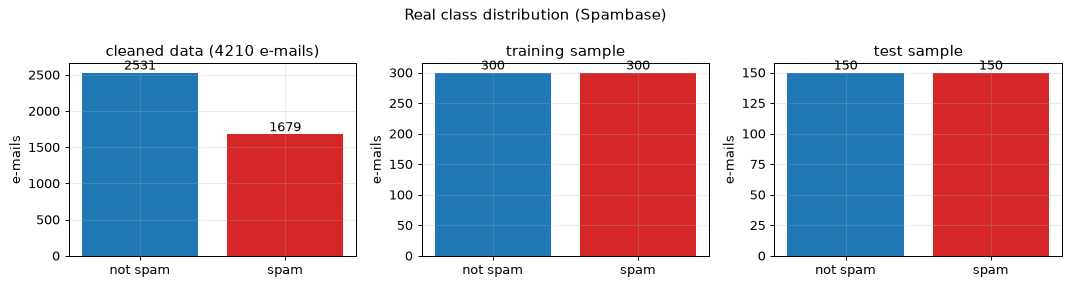

In [6]:
print("cleaned data set shape        :", df.shape, "(rows, 57 features + label)")
print("number of features             :", len(feature_names))
print("feature names                  :", feature_names)
print("original label values (UCI)    : 1 = spam, 0 = not spam")
print("class counts, cleaned data     :", {NAME[k]: int(v) for k, v in df["is_spam"].value_counts().sort_index().items()})
print("class counts, training sample  :", {NAME[k]: int(v) for k, v in zip(*np.unique(y_tr, return_counts=True))})
print("class counts, test sample      :", {NAME[k]: int(v) for k, v in zip(*np.unique(y_te, return_counts=True))})
display(df[feature_names].describe().T[["mean", "std", "min", "max"]].head(8))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for a, (title, lab) in zip(ax, [(f"cleaned data ({len(df)} e-mails)", y_all), ("training sample", y_tr), ("test sample", y_te)]):
    cnt = np.bincount(lab, minlength=2)
    a.bar([NAME[0], NAME[1]], cnt, color=[COL[0], COL[1]])
    for i, c in enumerate(cnt): a.text(i, c, str(c), ha="center", va="bottom")
    a.set_title(title); a.set_ylabel("e-mails")
plt.suptitle("Real class distribution (Spambase)"); plt.tight_layout(); plt.show()

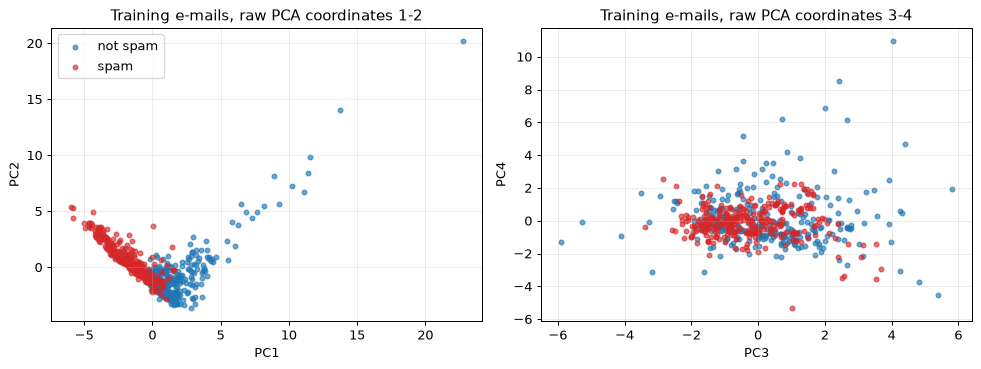

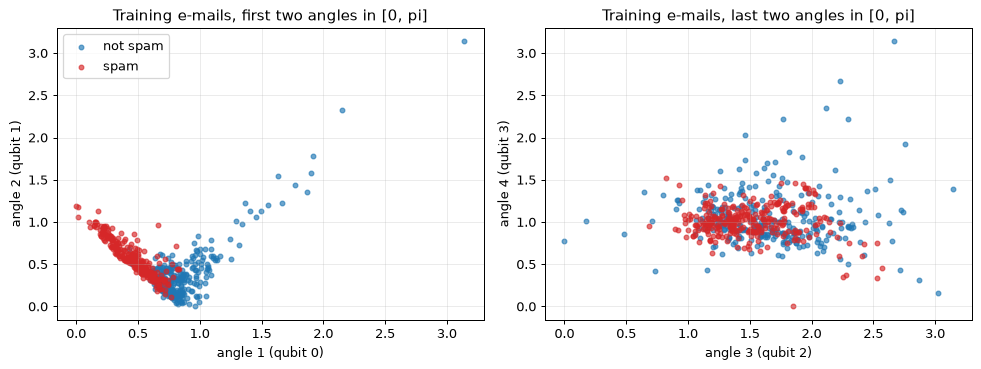

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k in (0, 1):
    m = y_tr == k
    ax[0].scatter(Z_tr[m, 0], Z_tr[m, 1], s=14, alpha=0.65, c=COL[k], label=NAME[k])
    ax[1].scatter(Z_tr[m, 2], Z_tr[m, 3], s=14, alpha=0.65, c=COL[k], label=NAME[k])
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].set_title("Training e-mails, raw PCA coordinates 1-2")
ax[1].set_xlabel("PC3"); ax[1].set_ylabel("PC4"); ax[1].set_title("Training e-mails, raw PCA coordinates 3-4")
ax[0].legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k in (0, 1):
    m = y_tr == k
    ax[0].scatter(A_tr[m, 0], A_tr[m, 1], s=14, alpha=0.65, c=COL[k], label=NAME[k])
    ax[1].scatter(A_tr[m, 2], A_tr[m, 3], s=14, alpha=0.65, c=COL[k], label=NAME[k])
ax[0].set_xlabel("angle 1 (qubit 0)"); ax[0].set_ylabel("angle 2 (qubit 1)"); ax[0].set_title("Training e-mails, first two angles in [0, pi]")
ax[1].set_xlabel("angle 3 (qubit 2)"); ax[1].set_ylabel("angle 4 (qubit 3)"); ax[1].set_title("Training e-mails, last two angles in [0, pi]")
ax[0].legend(); plt.tight_layout(); plt.show()

The two classes overlap in the first four principal components. In the plane of the first two angles the spam e-mails
(red) lie on a thin curved band at small angle 1 and large angle 2, while the not-spam e-mails (blue) fill the region at
larger angle 1 and contain a handful of far outliers (the points near angle 3 in the upper right); the two bands touch
around angle 1 = 0.4 to 0.6. The last two angles carry almost no class information. That is useful for this notebook: a
classifier cannot reach 100 %, so the effect of attacks on its margin is visible.

## 3. Classical baselines on the identical four angles

The same four angles (not the 57 raw features) go into SVC(rbf), a random forest (itself a bagged ensemble of trees), a
bagged SVC with as many members as the quantum bag (bootstrap samples, hard-vote), and a single decision tree. The 57-feature
random forest is shown for reference only. Mean +/- std over `N_REPEATS` seeds (the SVC is deterministic; the forests and the
bagging seeds change).

In [8]:
def acc(model, A, y): return accuracy_score(y, model.predict(A))

rows = []
def add(name, vals): rows.append({"model": name, "test accuracy": f"{100*np.mean(vals):.1f} +/- {100*np.std(vals):.1f} %", "_mean": np.mean(vals)})
add("single SVC(rbf, C=1)", [acc(SVC(C=1.0).fit(A_tr, y_tr), A_te, y_te)] * 1)
add("single decision tree", [acc(DecisionTreeClassifier(random_state=SEED + r).fit(A_tr, y_tr), A_te, y_te) for r in range(N_REPEATS)])
add("random forest (100 trees)", [acc(RandomForestClassifier(100, random_state=SEED + r, n_jobs=1).fit(A_tr, y_tr), A_te, y_te) for r in range(N_REPEATS)])
add(f"bagged SVC ({N_MEMBERS} members)", [acc(BaggingClassifier(SVC(C=1.0), n_estimators=N_MEMBERS, random_state=SEED + r, n_jobs=1).fit(A_tr, y_tr), A_te, y_te) for r in range(N_REPEATS)])
rf57 = RandomForestClassifier(100, random_state=SEED, n_jobs=1).fit(X_all[tr_idx], y_tr)
add("(reference) RF on all 57 log1p features", [rf57.score(X_all[te_idx], y_te)])
base_tbl = pd.DataFrame(rows); display(base_tbl.drop(columns="_mean"))
SVC_ACC = base_tbl.loc[0, "_mean"]; BAGSVC_ACC = base_tbl.loc[3, "_mean"]

,model,test accuracy
0,"single SVC(rbf, C=1)",88.0 +/- 0.0 %
1,single decision tree,86.0 +/- 0.6 %
2,random forest (100 trees),89.1 +/- 0.3 %
3,bagged SVC (31 members),88.3 +/- 0.2 %
4,(reference) RF on all 57 log1p features,93.3 +/- 0.0 %


## 4. Section III of the paper: robust statistics, checked on real e-mails

Section III proposes a robust PCA in which every mean is replaced by a median. Its quantum cost (Theorem 5 (1)) cannot be
tested on a classical computer, but three of its ingredients are plain mathematics and can be checked on data:

* **Lemma 3**: any vectors of norm <= R can be embedded as unit vectors with the same inner products (up to 1/R^2).
* **Lemma 4**: if an adversary changes a fraction alpha of the data, the median moves by at most alpha L, where L is the
  Lipschitz constant of the inverse CDF. The mean has no such bound.
* **Theorem 5 (2)**: the robust PCA matrix of Definition 1 moves by at most 5 alpha L (d + 2) in spectral norm.

"Normal traffic" for this section is the unlabeled not-spam e-mails of the training pool, in the four principal components
fitted on the training sample (the adversary of Threat Model 1 controls a fraction alpha of the vectors the algorithm sees).

In [9]:
# --- Lemma 3: embedding of vectors with norm <= R as unit vectors, <x_j^dagger | x_k> = <x_j, x_k> / R^2 ---------------
def lemma3_embed(Xv, R):
    Nv, N = Xv.shape
    A = np.zeros((Nv, N * (2 * Nv + 1))); B = np.zeros_like(A)
    for j, x in enumerate(Xv):
        nrm = np.linalg.norm(x); u = x / nrm
        sa = np.zeros(2 * Nv + 1); sa[0] = nrm / R; sa[1 + j] = np.sqrt(max(0.0, 1 - (nrm / R) ** 2))
        sb = np.zeros(2 * Nv + 1); sb[0] = nrm / R; sb[1 + Nv + j] = np.sqrt(max(0.0, 1 - (nrm / R) ** 2))
        A[j] = np.kron(u, sa); B[j] = np.kron(u, sb)           # |x_j> and |x_j^dagger> of Eq. (3)
    return A, B

Xv = Z_tr[:12]                                  # twelve real training e-mails (raw PCA coordinates)
for R in (np.linalg.norm(Xv, axis=1).max(), 3.0 * np.linalg.norm(Xv, axis=1).max()):
    A, B = lemma3_embed(Xv, R)
    err_ip   = np.abs(B @ A.T - Xv @ Xv.T / R ** 2).max()
    err_unit = max(np.abs(np.linalg.norm(A, axis=1) - 1).max(), np.abs(np.linalg.norm(B, axis=1) - 1).max())
    print(f"R = {R:6.3f}: Hilbert-space dimension {A.shape[1]} = N(2Nv+1) = {4*(2*len(Xv)+1)}; "
          f"max |<x^dag_j|x_k> - <x_j,x_k>/R^2| = {err_ip:.2e}; max | ||state|| - 1 | = {err_unit:.2e}")
LEMMA3_ERR = float(err_ip)
assert LEMMA3_ERR < 1e-12

R =  6.067: Hilbert-space dimension 100 = N(2Nv+1) = 100; max |<x^dag_j|x_k> - <x_j,x_k>/R^2| = 1.11e-16; max | ||state|| - 1 | = 1.11e-16
R = 18.201: Hilbert-space dimension 100 = N(2Nv+1) = 100; max |<x^dag_j|x_k> - <x_j,x_k>/R^2| = 2.78e-17; max | ||state|| - 1 | = 2.22e-16


normal training vectors: (1772, 4)


,L_max,median_shift_max,bound_max,tightness_max,mean_over_median,all_hold
alpha,,,,,,
0.050254,7.3229,0.2159,0.3680,0.7249,693.3472,True
0.099944,7.3293,0.4294,0.7325,0.7523,615.5620,True
0.150198,7.3271,0.6208,1.1005,0.7331,586.1404,True
0.199887,7.3293,0.8401,1.4650,0.7185,570.2291,True
0.250141,7.4325,1.0600,1.8592,0.7348,548.6945,True
0.299831,13.4487,1.4430,4.0323,0.6165,474.8634,True
0.350085,13.6113,1.8748,4.7651,0.6003,427.8126,True
0.399774,32.1604,2.7550,12.8569,0.3952,349.3262,True
0.450028,94.7541,5.6134,42.6420,0.3569,218.2751,True


Lemma 4 bound |median(P) - median(Q)| <= alpha L holds in all 36 cases: True


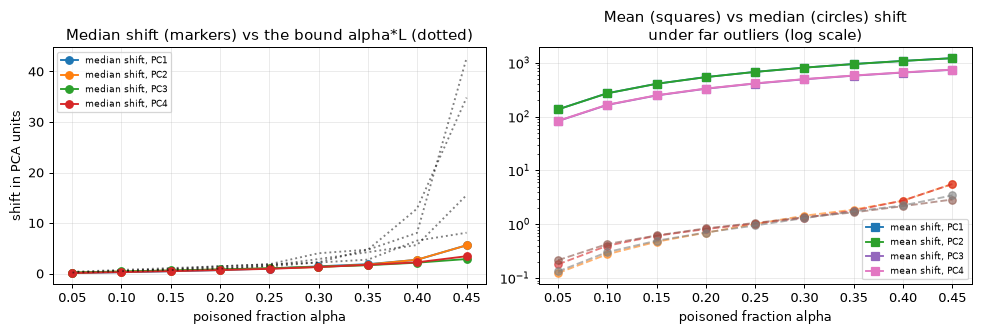

In [10]:
# --- Lemma 4: the median moves by at most alpha*L, the mean does not --------------------------------------------------
NORMAL = pca.transform(scaler.transform(X_all[pool_tr][y_all[pool_tr] == 0]))      # unlabeled "normal" e-mails of the training pool
n_norm, d_pca = NORMAL.shape
print("normal training vectors:", NORMAL.shape)

def grid_slope(x, a_eff, step=0.01):
    """Largest secant slope of the empirical quantile function on [1/2 - a_eff, 1/2 + a_eff] (grid contains 1/2)."""
    K = 2 * max(1, int(round(a_eff / step))) + 1
    u = np.linspace(0.5 - a_eff, 0.5 + a_eff, K)
    q = np.quantile(x, u)
    return float(np.max(np.abs(np.diff(q)) / np.diff(u)))

rows = []
BIG = 1e3                                        # the adversary's outlier magnitude (R in the paper), in units of the data scale
for alpha in LEMMA4_ALPHAS:
    a = int(round(alpha * (n_norm - 1))); a_eff = a / (n_norm - 1)
    for k in range(d_pca):
        x = NORMAL[:, k]; sd = x.std(); order = np.argsort(x)
        med0, mean0 = np.median(x), x.mean()
        shifts_med, shifts_mean = [], []
        for sign in (+1, -1):                    # worst case for the median: replace the a points on one side by far outliers on the other
            xp = x.copy(); idx = order[:a] if sign > 0 else order[-a:]
            xp[idx] = sign * BIG * sd + med0
            shifts_med.append(abs(np.median(xp) - med0)); shifts_mean.append(abs(xp.mean() - mean0))
        L = grid_slope(x, a_eff)
        rows.append(dict(alpha=a_eff, feature=f"PC{k+1}", L=L, median_shift=max(shifts_med), bound_alpha_L=a_eff * L,
                         holds=max(shifts_med) <= a_eff * L + 1e-9, mean_shift=max(shifts_mean)))
L4 = pd.DataFrame(rows)
L4["tightness (shift / bound)"] = L4["median_shift"] / L4["bound_alpha_L"]
L4["mean shift / median shift"] = L4["mean_shift"] / L4["median_shift"]
display(L4.groupby("alpha").agg(L_max=("L", "max"), median_shift_max=("median_shift", "max"), bound_max=("bound_alpha_L", "max"),
                                tightness_max=("tightness (shift / bound)", "max"), mean_over_median=("mean shift / median shift", "median"),
                                all_hold=("holds", "all")).round(4))
LEMMA4_HOLDS = bool(L4["holds"].all())
print("Lemma 4 bound |median(P) - median(Q)| <= alpha L holds in all", len(L4), "cases:", LEMMA4_HOLDS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k in range(d_pca):
    s = L4[L4.feature == f"PC{k+1}"]
    ax[0].plot(s.alpha, s.median_shift, "o-", label=f"median shift, PC{k+1}"); ax[0].plot(s.alpha, s.bound_alpha_L, "k:", alpha=0.5)
    ax[1].semilogy(s.alpha, s.mean_shift, "s-", label=f"mean shift, PC{k+1}"); ax[1].semilogy(s.alpha, s.median_shift, "o--", alpha=0.6)
ax[0].set_title("Median shift (markers) vs the bound alpha*L (dotted)"); ax[0].set_xlabel("poisoned fraction alpha"); ax[0].set_ylabel("shift in PCA units"); ax[0].legend(fontsize=7)
ax[1].set_title("Mean (squares) vs median (circles) shift\nunder far outliers (log scale)"); ax[1].set_xlabel("poisoned fraction alpha"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [11]:
# --- Theorem 5 (2): || M - M' ||_2 <= 5 alpha L (d + 2) for the robust PCA matrix of Definition 1 ------------------------
def robust_M(X):
    c = X - np.median(X, 0); d = X.shape[1]; M = np.empty((d, d))
    for k in range(d):
        for l in range(k, d):
            M[k, l] = M[l, k] = np.median(c[:, k] * c[:, l])      # Definition 1: median of products of centred coordinates
    return M

def cov_M(X): return np.cov(X.T, bias=True)                        # the ordinary (mean-based) PCA matrix

def thm5_L(X, a_eff):
    c = X - np.median(X, 0); d = X.shape[1]
    Ls = [grid_slope(X[:, k], a_eff) for k in range(d)] + [grid_slope(c[:, k] * c[:, l], a_eff) for k in range(d) for l in range(k, d)]
    return max(Ls)

M0, S0 = robust_M(NORMAL), cov_M(NORMAL)
R_ADV = 20.0 * np.median(np.linalg.norm(NORMAL, axis=1))          # CHOICE: the adversary may use vectors up to 20x the typical norm
rg = np.random.default_rng(SEED)
dirs = [s * np.eye(d_pca)[k] for k in range(d_pca) for s in (1, -1)]
dirs += [(np.eye(d_pca)[k] + s * np.eye(d_pca)[l]) / np.sqrt(2) for k in range(d_pca) for l in range(k + 1, d_pca) for s in (1, -1)]
dirs += list(rg.standard_normal((100, d_pca)) / 1.0)
dirs = [v / np.linalg.norm(v) for v in dirs]

rows = []
for alpha in [0.05, 0.10, 0.20, 0.30, 0.40]:
    a = int(round(alpha * (n_norm - 1))); a_eff = a / (n_norm - 1)
    L = thm5_L(NORMAL, a_eff)
    pos = rg.choice(n_norm, a, replace=False)
    best_rob, best_cov = 0.0, 0.0
    def damage(u):
        Xp = NORMAL.copy(); Xp[pos] = R_ADV * u
        return np.linalg.norm(robust_M(Xp) - M0, 2), np.linalg.norm(cov_M(Xp) - S0, 2)
    cand = []
    for u in dirs:
        r_, c_ = damage(u); cand.append((r_, u)); best_cov = max(best_cov, c_)
    cand.sort(key=lambda t: -t[0]); u = cand[0][1]; best_rob = cand[0][0]
    for step in range(60):                                          # hill-climb the direction against the robust matrix
        v = u + 0.3 * rg.standard_normal(d_pca) * (0.95 ** step); v /= np.linalg.norm(v)
        r_, c_ = damage(v); best_cov = max(best_cov, c_)
        if r_ > best_rob: best_rob, u = r_, v
    bound = 5 * a_eff * L * (d_pca + 2)
    rows.append(dict(alpha=a_eff, L=L, robust_shift=best_rob, bound_5_alpha_L_d2=bound, ratio=best_rob / bound, mean_based_shift=best_cov, holds=best_rob <= bound))
T5 = pd.DataFrame(rows); display(T5.round(4))
THM5_HOLDS = bool(T5["holds"].all()); THM5_RATIO = float(T5["ratio"].max())
print("Theorem 5(2) bound holds for every alpha and every attack tried:", THM5_HOLDS, "| largest shift / bound = %.3f" % THM5_RATIO)
print("mean-based PCA matrix shift at alpha=0.4 is %.1f times the robust one (adversary norm R = %.1f)" % (T5.mean_based_shift.iloc[-1] / T5.robust_shift.iloc[-1], R_ADV))

,alpha,L,robust_shift,bound_5_alpha_L_d2,ratio,mean_based_shift,holds
0,0.0503,8.0789,0.3154,12.1799,0.0259,169.8107,True
1,0.0999,8.0056,0.7290,24.0031,0.0304,320.1882,True
2,0.1999,9.5185,2.3879,57.0785,0.0418,569.1262,True
3,0.2998,22.2854,6.5226,200.4554,0.0325,746.5228,True
4,0.3998,151.3111,23.6034,1814.7076,0.0130,853.7155,True


Theorem 5(2) bound holds for every alpha and every attack tried: True | largest shift / bound = 0.042
mean-based PCA matrix shift at alpha=0.4 is 36.2 times the robust one (adversary norm R = 57.7)


,alpha,"AUC standard PCA, spike","AUC robust PCA (Def. 1), spike","AUC standard PCA, mimicry","AUC robust PCA (Def. 1), mimicry"
0,0.00,0.862,0.538,0.862,0.538
1,0.05,0.862,0.406,0.842,0.440
2,0.10,0.859,0.448,0.817,0.484
3,0.20,0.869,0.450,0.786,0.514
4,0.30,0.868,0.516,0.683,0.342


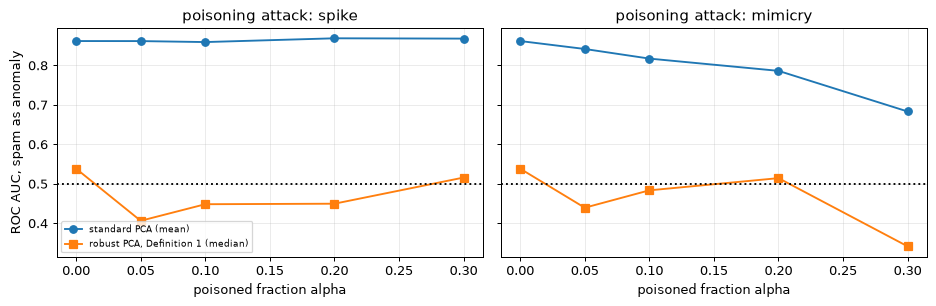

mimicry attack, AUC clean -> alpha=0.3: standard 0.862 -> 0.683 | robust 0.538 -> 0.342 | gain of the robust matrix under attack -0.342


In [12]:
# --- Does the robust matrix help a PCA anomaly detector under poisoning? (the use case that motivates Section III) -------
# Normal data: not-spam e-mails of the training pool (57 log1p features, robust-scaled). Anomalies: spam in the test pool.
# Detector: squared projection of (x - centre) on the r smallest-variance eigenvectors of the PCA matrix (the paper's rule).
# Two poisoning attacks (Threat Model 1: the adversary replaces a fraction alpha of the normal training vectors):
#   "spike"  : far vectors along the direction in which spam differs from normal traffic (inflates its variance);
#   "mimicry": real spam e-mails injected as if they were normal traffic (the boiling-frog / Tay-style attack).
norm_tr = X_all[pool_tr][y_all[pool_tr] == 0]
rs = RobustScaler().fit(norm_tr)
H = rs.transform(norm_tr); T = rs.transform(X_all[pool_te]); yT = y_all[pool_te]
spam_tr_rows = rs.transform(X_all[pool_tr][y_all[pool_tr] == 1])
spam_dir = spam_tr_rows.mean(0) - H.mean(0); spam_dir /= np.linalg.norm(spam_dir)
s_u = (H @ spam_dir).std(); d_all = H.shape[1]; R_LOW = 10               # CHOICE: r = 10 low-variance directions

def robust_M_fast(X):
    c = X - np.median(X, 0); M = np.empty((X.shape[1],) * 2)
    for k in range(X.shape[1]):
        M[k, k:] = np.median(c[:, [k]] * c[:, k:], 0); M[k:, k] = M[k, k:]
    return M, np.median(X, 0)

def det_auc(Mx, ctr):
    w, V = np.linalg.eigh(Mx); low = V[:, :R_LOW]
    return roc_auc_score(yT, (((T - ctr) @ low) ** 2).sum(1))

rg2 = np.random.default_rng(SEED); rows = []
for alpha in DET_ALPHAS:
    a = int(alpha * len(H)); row = dict(alpha=alpha)
    for attack in ("spike", "mimicry"):
        P = H.copy()
        if a:
            idx = rg2.choice(len(H), a, replace=False)
            if attack == "spike":
                P[idx] = H.mean(0) + 15 * s_u * spam_dir * rg2.choice([-1, 1], a)[:, None] + 0.1 * rg2.standard_normal((a, d_all))
            else:
                P[idx] = spam_tr_rows[rg2.choice(len(spam_tr_rows), a, replace=False)]
        row[f"AUC standard PCA, {attack}"] = det_auc(np.cov(P.T), P.mean(0))
        Mr, cr = robust_M_fast(P); row[f"AUC robust PCA (Def. 1), {attack}"] = det_auc(Mr, cr)
    rows.append(row)
DET = pd.DataFrame(rows); display(DET.round(3))
DET_GAIN = float(DET["AUC robust PCA (Def. 1), mimicry"].iloc[-1] - DET["AUC standard PCA, mimicry"].iloc[-1])
DET_CLEAN = (float(DET["AUC standard PCA, mimicry"].iloc[0]), float(DET["AUC robust PCA (Def. 1), mimicry"].iloc[0]))
DET_ATK = (float(DET["AUC standard PCA, mimicry"].iloc[-1]), float(DET["AUC robust PCA (Def. 1), mimicry"].iloc[-1]))
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5), sharey=True)
for a_, attack in zip(ax, ("spike", "mimicry")):
    a_.plot(DET.alpha, DET[f"AUC standard PCA, {attack}"], "o-", label="standard PCA (mean)")
    a_.plot(DET.alpha, DET[f"AUC robust PCA (Def. 1), {attack}"], "s-", label="robust PCA, Definition 1 (median)")
    a_.axhline(0.5, c="k", ls=":"); a_.set_xlabel("poisoned fraction alpha"); a_.set_title(f"poisoning attack: {attack}")
ax[0].set_ylabel("ROC AUC, spam as anomaly"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print("mimicry attack, AUC clean -> alpha=%.1f: standard %.3f -> %.3f | robust %.3f -> %.3f | gain of the robust matrix under attack %+.3f"
      % (max(DET_ALPHAS), DET_CLEAN[0], DET_ATK[0], DET_CLEAN[1], DET_ATK[1], DET_GAIN))

**Reading the numbers.** Lemma 3, Lemma 4 and Theorem 5 (2) hold exactly as stated; the bound of Theorem 5 (2) is very loose
(the largest shift is about 4 % of it). The mean-based matrix moves by an amount that grows with the adversary's vector norm,
the median-based one does not (36 times less at alpha = 0.4 with norm R = 57.7): that is the paper's point and it is reproduced.
The last experiment asks the practical question: does the Definition-1 matrix make a PCA anomaly detector on real spam
features *better*? No. Definition 1 takes the median of a product of two centred coordinates, and most Spambase word frequencies
are exactly zero for most e-mails, so many medians are 0 and the matrix is a poor substitute for the covariance on this kind of
data: its clean AUC is 0.54 (ordinary PCA 0.86) and it wanders between 0.34 and 0.54 under attack. The ordinary detector does
lose accuracy under the spam-mimicry attack (0.86 to 0.68 at alpha = 0.3) but it stays far above the robust matrix. Robustness is
bought with accuracy, and on this data the clean detector is not better. This is a limit of the *method*, not of the quantum
algorithm that would compute it.

## 5. Section IV: the quantum bag of classifiers

**Members.** The paper wants each C_j to be a Hermitian *unitary* whose eigenvalues are +1 and -1, so that a test state
|psi> splits into a part a|phi_+> in the +1 eigenspace and a part in the -1 eigenspace. A variational quantum classifier is
exactly that: encode the e-mail as a state |psi(x)>, apply a trained circuit V_j(theta_j), and measure Z on qubit 0. The
classifier observable is

C_j = V_j^dagger Z_0 V_j,   C_j^2 = 1,   class of x = sign <psi(x)|C_j|psi(x)>.

**Training.** Every member is trained on its own bootstrap sample (n draws with replacement from the n training e-mails)
by minimising the squared loss between <Z_0> and the label (+1 spam, -1 not spam) with COBYLA. A single "non-bagged" VQC
is trained the same way on the whole training sample.

**Fast and exact simulation.** Training needs thousands of circuit evaluations. The helper below applies the ansatz gate list
to a 16 x 16 matrix with numpy; the cell after it **asserts that it equals the Qiskit circuit** (`Operator` of the ansatz, and
`Statevector.expectation_value` of the full encode + ansatz circuit) before it is used for anything.

In [13]:
DIM = 2 ** N_QUBITS
xs = ParameterVector("x", N_QUBITS)
feature_map = QuantumCircuit(N_QUBITS, name="encode")
for i in range(N_QUBITS):
    feature_map.ry(xs[i], i)                                              # CHOICE: product-state (angle) encoding, one angle per qubit
ansatz = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS, entanglement="full")  # CHOICE: ansatz of the member classifiers
N_PARAMS = ansatz.num_parameters
member_circuit = feature_map.compose(ansatz)                              # then: measure Z on qubit 0

_pidx = {p: i for i, p in enumerate(ansatz.parameters)}
GATES = []
for inst in ansatz.data:                                                  # the simulator is built from the gate list of the real circuit
    nm = inst.operation.name; qs = [ansatz.find_bit(q).index for q in inst.qubits]
    if nm == "ry":
        GATES.append(("ry", qs[0], _pidx[inst.operation.params[0]]))
    elif nm == "cx":
        c, t = qs; GATES.append(("cx", np.array([i ^ (1 << t) if (i >> c) & 1 else i for i in range(DIM)])))
    else:
        raise ValueError("unexpected gate " + nm)

def ansatz_matrix(theta):
    """16 x 16 real matrix V(theta) of the ansatz (rows = output basis state), little-endian like Qiskit."""
    V = np.eye(DIM)
    for g in GATES:
        if g[0] == "ry":
            q, th = g[1], theta[g[2]]; c, s = np.cos(th / 2), np.sin(th / 2)
            A = V.reshape(2 ** (N_QUBITS - 1 - q), 2, 2 ** q, DIM); out = np.empty_like(A)
            out[:, 0] = c * A[:, 0] - s * A[:, 1]; out[:, 1] = s * A[:, 0] + c * A[:, 1]
            V = out.reshape(DIM, DIM)
        else:
            V = V[g[1]]
    return V

Z0 = np.array([1.0 if (i & 1) == 0 else -1.0 for i in range(DIM)])        # Z on qubit 0 (least significant bit)
def member_observable(theta):
    V = ansatz_matrix(theta); return V.T @ (Z0[:, None] * V)               # C = V^T Z0 V (V is real)

# ---- equivalence with the real Qiskit circuits -------------------------------------------------------------------------
rt = np.random.default_rng(SEED)
errs_u, errs_e = [], []
for _ in range(5):
    th = rt.uniform(0, 2 * np.pi, N_PARAMS); a = rt.uniform(0, np.pi, N_QUBITS)
    errs_u.append(np.abs(ansatz_matrix(th) - Operator(ansatz.assign_parameters(th)).data).max())
    sv = Statevector(member_circuit.assign_parameters({**dict(zip(xs, a)), **dict(zip(ansatz.parameters, th))}))
    q_exp = sv.expectation_value(SparsePauliOp("I" * (N_QUBITS - 1) + "Z")).real
    psi = Statevector(feature_map.assign_parameters(a)).data.real
    errs_e.append(abs(q_exp - psi @ member_observable(th) @ psi))
print(f"max |V_numpy - Operator(Qiskit ansatz)| over 5 random thetas      : {max(errs_u):.2e}")
print(f"max |<Z_0> Qiskit statevector - psi^T C psi| over 5 random points : {max(errs_e):.2e}")
assert max(errs_u) < 1e-12 and max(errs_e) < 1e-12, "numpy simulator differs from the Qiskit circuit"

t0 = time.time()
def encode_states(A):
    S = np.array([Statevector(feature_map.assign_parameters(a)).data for a in A])
    assert np.abs(S.imag).max() < 1e-12; return S.real                     # RY product states are real vectors
S_tr, S_te = encode_states(A_tr), encode_states(A_te)
print(f"encoded {len(S_tr)} + {len(S_te)} e-mails with the Qiskit circuit in {time.time()-t0:.1f} s; state matrix {S_tr.shape}")

max |V_numpy - Operator(Qiskit ansatz)| over 5 random thetas      : 0.00e+00
max |<Z_0> Qiskit statevector - psi^T C psi| over 5 random points : 2.64e-16


encoded 600 + 300 e-mails with the Qiskit circuit in 0.9 s; state matrix (600, 16)


In [14]:
def expectation_all(Cs, S):                       # (M, n) matrix of <psi_i|C_j|psi_i> for real symmetric C_j and real states
    return np.einsum("ni,jik,nk->jn", S, np.asarray(Cs), S)

def train_member(S, y01, seed, maxiter):
    r = np.random.default_rng(seed); th0 = r.uniform(0, 2 * np.pi, N_PARAMS); yy = 2.0 * y01 - 1.0
    loss = lambda t: np.mean((((S @ ansatz_matrix(t).T) ** 2) @ Z0 - yy) ** 2)
    return minimize(loss, th0, method="COBYLA", options={"maxiter": maxiter}).x

def build_ensemble(S, y01, M, seed, maxiter, bootstrap=True):
    thetas, inbag = [], []
    for j in range(M):
        r = np.random.default_rng(seed * 1000 + j)
        bi = r.integers(0, len(y01), len(y01)) if bootstrap else np.arange(len(y01))          # bootstrap: draw n with replacement
        thetas.append(train_member(S[bi], y01[bi], seed * 1000 + 500 + j, maxiter)); inbag.append(np.unique(bi))
    return dict(thetas=thetas, C=np.array([member_observable(t) for t in thetas]), inbag=inbag)

def pplus_all(C, S):
    """Definition 6: probability of projecting the test state onto the positive eigenspace of C = mean of the C_j (real case)."""
    w, V = np.linalg.eigh(C); return ((S @ V) ** 2)[:, w > 0].sum(1)

def decisions(ens, S):
    ex = expectation_all(ens["C"], S)                                        # member expectations
    return dict(member_mean=[((e > 0)) for e in ex], expectation=(ex.mean(0) > 0), eigen=(pplus_all(ens["C"].mean(0), S) > 0.5),
                majority=((ex > 0).mean(0) > 0.5))

def acc_of(pred, y01): return float(np.mean(pred.astype(int) == y01))

t0 = time.time()
single = [build_ensemble(S_tr, y_tr, 1, SEED + 10 * r, MAXITER, bootstrap=False) for r in range(N_REPEATS)]
print(f"{N_REPEATS} single VQCs trained in {time.time()-t0:.1f} s ({(time.time()-t0)/N_REPEATS:.1f} s each)")
t0 = time.time()
ENS = [build_ensemble(S_tr, y_tr, N_MEMBERS, SEED + 10 * r + 1, MAXITER) for r in range(N_REPEATS)]
print(f"{N_REPEATS} bags of {N_MEMBERS} members trained in {time.time()-t0:.1f} s")

5 single VQCs trained in 10.9 s (2.2 s each)


5 bags of 31 members trained in 357.4 s


,model,test accuracy
0,single VQC,87.3 +/- 1.3 %
1,mean member (bootstrap),86.5 +/- 0.3 %
2,bag: sign of mean <C> (Eq. 8),88.4 +/- 0.8 %
3,bag: eigenspace projection (Def. 6),88.2 +/- 0.9 %
4,bag: majority vote,88.3 +/- 0.4 %
5,"single SVC(rbf, C=1)",88.0 +/- 0.0 %
6,single decision tree,86.0 +/- 0.6 %
7,random forest (100 trees),89.1 +/- 0.3 %
8,bagged SVC (31 members),88.3 +/- 0.2 %
9,(reference) RF on all 57 log1p features,93.3 +/- 0.0 %


agreement of the two quantum readouts (Eq. 8 vs Definition 6) on the test set: 99.3 %
fraction of training e-mails left out of a bootstrap sample: 36.8 %   (theory 1/e = 36.8 % for n -> infinity)


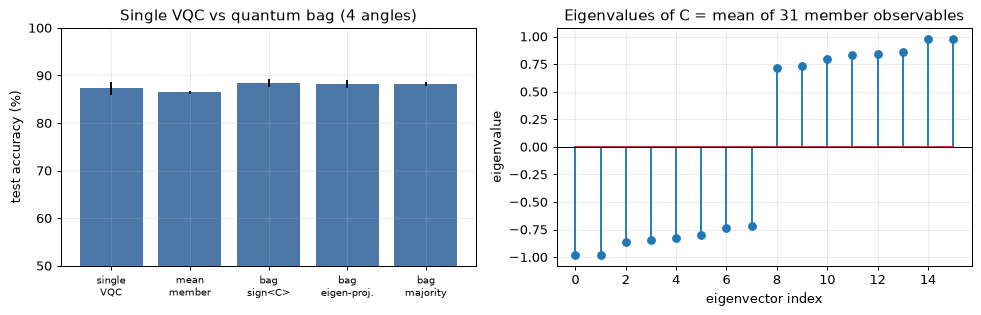

smallest |eigenvalue| of C: 0.716  ->  gamma = 2 min|E| = 1.431, Corollary 10 radius gamma/4 = 0.358 (= 11.1 of 31 members)


In [15]:
res = {k: [] for k in ["single VQC", "mean member (bootstrap)", "bag: sign of mean <C> (Eq. 8)", "bag: eigenspace projection (Def. 6)", "bag: majority vote"]}
for r in range(N_REPEATS):
    d1 = decisions(single[r], S_te); res["single VQC"].append(acc_of(d1["expectation"], y_te))
    d = decisions(ENS[r], S_te)
    res["mean member (bootstrap)"].append(np.mean([acc_of(m, y_te) for m in d["member_mean"]]))
    res["bag: sign of mean <C> (Eq. 8)"].append(acc_of(d["expectation"], y_te))
    res["bag: eigenspace projection (Def. 6)"].append(acc_of(d["eigen"], y_te))
    res["bag: majority vote"].append(acc_of(d["majority"], y_te))
tbl = pd.DataFrame({"model": list(res), "test accuracy": [f"{100*np.mean(v):.1f} +/- {100*np.std(v):.1f} %" for v in res.values()], "_m": [np.mean(v) for v in res.values()]})
tbl = pd.concat([tbl, base_tbl[["model", "test accuracy", "_mean"]].rename(columns={"_mean": "_m"})], ignore_index=True)
display(tbl.drop(columns="_m"))
ACC = dict(zip(tbl.model, tbl._m)); SINGLE_ACC = ACC["single VQC"]; BAG_ACC = ACC["bag: eigenspace projection (Def. 6)"]
AGREE = np.mean([np.mean(decisions(ENS[r], S_te)["expectation"] == decisions(ENS[r], S_te)["eigen"]) for r in range(N_REPEATS)])
print(f"agreement of the two quantum readouts (Eq. 8 vs Definition 6) on the test set: {100*AGREE:.1f} %")

# bootstrap out-of-bag fraction ("each training set excludes a constant fraction of the training examples")
oob = np.mean([1 - len(ib) / len(y_tr) for ib in ENS[0]["inbag"]])
print(f"fraction of training e-mails left out of a bootstrap sample: {100*oob:.1f} %   (theory 1/e = {100/np.e:.1f} % for n -> infinity)")
OOB_FRAC = float(oob)

C_bag = ENS[0]["C"].mean(0); w_bag = np.linalg.eigvalsh(C_bag)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(range(len(res)), [100 * np.mean(v) for v in res.values()], yerr=[100 * np.std(v) for v in res.values()], color="#4c78a8")
ax[0].set_xticks(range(len(res))); ax[0].set_xticklabels(["single\nVQC", "mean\nmember", "bag\nsign<C>", "bag\neigen-proj.", "bag\nmajority"], fontsize=8)
ax[0].set_ylim(50, 100); ax[0].set_ylabel("test accuracy (%)"); ax[0].set_title("Single VQC vs quantum bag (4 angles)")
ax[1].stem(range(DIM), w_bag); ax[1].axhline(0, c="k", lw=0.8)
ax[1].set_title(f"Eigenvalues of C = mean of {N_MEMBERS} member observables"); ax[1].set_xlabel("eigenvector index"); ax[1].set_ylabel("eigenvalue")
plt.tight_layout(); plt.show()
print("smallest |eigenvalue| of C: %.3f  ->  gamma = 2 min|E| = %.3f, Corollary 10 radius gamma/4 = %.3f (= %.1f of %d members)" %
      (np.abs(w_bag).min(), 2 * np.abs(w_bag).min(), np.abs(w_bag).min() / 2, N_MEMBERS * np.abs(w_bag).min() / 2, N_MEMBERS))

## 6. Definition 6 as a real circuit: phase estimation of e^{-iC}

The paper reads the ensemble out with **phase estimation**: prepare the test state on the 4 system qubits, put `m` evaluation
qubits in |+>, apply controlled powers of U = exp(-i tau C), run the inverse QFT, and read the evaluation register. Every
eigenvector |E_n> of C in the support of the test state returns an integer j with probability concentrated near
phi_n 2^m, where e^{2 pi i phi_n} is the eigenphase of U, here phi_n = -tau E_n / (2 pi) = -E_n / 4 for tau = pi/2.
Because |E_n| <= 1, the phase lies in (-1/4, 1/4): positive eigenvalues land in the upper half of the register
(top bit 1) and negative ones in the lower half (top bit 0). The class is +1 if the probability of a top bit of 1 exceeds 1/2.

Three computations are compared and **asserted equal**: (a) the Qiskit statevector of the full circuit, (b) the textbook
phase-estimation distribution computed from the eigendecomposition of C, and (c) the ideal projector probability P(+) =
sum over E_n > 0 of |<E_n|psi>|^2 that is the limit of (a) as m grows. The controlled powers of U are inserted as exact
unitary boxes (`UnitaryGate`), i.e. no Hamiltonian-simulation error is added; Lemma 8's simulation cost is examined separately
in section 9.

In [16]:
def qpe_circuit(Cm, angles, m, tau=TAU):
    """Phase estimation of U = exp(-i tau C) on the encoded test state: system qubits 0..3, evaluation qubits 4..3+m."""
    qc = QuantumCircuit(N_QUBITS + m)
    qc.compose(feature_map.assign_parameters(angles), qubits=range(N_QUBITS), inplace=True)       # state preparation |psi(x)>
    for k in range(m): qc.h(N_QUBITS + k)
    for k in range(m):                                                                           # controlled U^(2^k)
        Uk = expm(-1j * tau * Cm * 2 ** k)
        big = np.block([[np.eye(DIM), np.zeros((DIM, DIM))], [np.zeros((DIM, DIM)), Uk]])
        qc.append(UnitaryGate(big, label=f"cU^{2**k}"), list(range(N_QUBITS)) + [N_QUBITS + k])
    qc.append(QFTGate(m).inverse(), range(N_QUBITS, N_QUBITS + m))
    return qc

def qpe_weights(Cm, m, tau=TAU):
    """W[j, n] = |amplitude of outcome j for eigenphase n|^2 (textbook phase estimation) and the eigen-decomposition of C."""
    w, V = np.linalg.eigh(Cm); phi = (-tau * w / (2 * np.pi)) % 1.0; K = 2 ** m
    k = np.arange(K)
    amp = np.exp(2j * np.pi * k[None, :, None] * (phi[None, None, :] - np.arange(K)[:, None, None] / K)).sum(1) / K
    return np.abs(amp) ** 2, w, V

def qpe_plus_prob(Cm, S, m):
    """P(top evaluation bit = 1) for every row of S from the analytic phase-estimation distribution."""
    W, w, V = qpe_weights(Cm, m); c2 = (S @ V) ** 2
    return (c2 @ W.T)[:, 2 ** (m - 1):].sum(1), c2 @ W.T

rows = []
for i in range(QPE_POINTS):
    qc = qpe_circuit(C_bag, A_te[i], QPE_BITS)
    p_q = Statevector(qc).probabilities(list(range(N_QUBITS, N_QUBITS + QPE_BITS)))
    p_a = qpe_plus_prob(C_bag, S_te[i:i + 1], QPE_BITS)[1][0]
    err = np.abs(p_q - p_a).max(); assert err < 1e-9, err                                      # circuit == textbook phase estimation
    shots = np.random.default_rng(SEED + i).multinomial(1000, p_q / p_q.sum())                 # 1000 measurement shots of the register
    p_shots = shots[2 ** (QPE_BITS - 1):].sum() / 1000
    rows.append(dict(test_email=i, true="spam" if y_te[i] else "not spam", P_plus_circuit=p_q[2 ** (QPE_BITS - 1):].sum(),
                     P_plus_textbook=p_a[2 ** (QPE_BITS - 1):].sum(), P_plus_exact_projector=pplus_all(C_bag, S_te[i:i + 1])[0],
                     P_plus_1000_shots=p_shots, max_prob_diff=err))
display(pd.DataFrame(rows).round(4))
print(f"Qiskit circuit ({N_QUBITS}+{QPE_BITS} = {N_QUBITS+QPE_BITS} qubits) equals the textbook phase-estimation distribution to {max(r['max_prob_diff'] for r in rows):.1e}")

# decision agreement with the ideal projector on the whole test set, as a function of the number of evaluation qubits
p_exact = pplus_all(C_bag, S_te); dec_exact = p_exact > 0.5
rows = []
for m in (3, 4, 5, 6, 7):
    p_m = qpe_plus_prob(C_bag, S_te, m)[0]
    rows.append(dict(evaluation_qubits=m, U_applications=2 ** m - 1, eigenvalue_resolution=4 / 2 ** m, mean_abs_P_error=np.mean(np.abs(p_m - p_exact)),
                     decision_agreement=np.mean((p_m > 0.5) == dec_exact), accuracy=acc_of(p_m > 0.5, y_te)))
QPE_TBL = pd.DataFrame(rows); display(QPE_TBL.round(4))
QPE_AGREE = float(QPE_TBL.loc[QPE_TBL.evaluation_qubits == QPE_BITS, "decision_agreement"].iloc[0])
print(f"ideal projector accuracy {100*acc_of(dec_exact, y_te):.1f} %; phase estimation with m={QPE_BITS}: decisions agree on {100*QPE_AGREE:.1f} % of the test e-mails")

,test_email,true,P_plus_circuit,P_plus_textbook,P_plus_exact_projector,P_plus_1000_shots,max_prob_diff
0,0,spam,0.6574,0.6574,0.6593,0.664,0.0
1,1,not spam,0.4222,0.4222,0.4206,0.417,0.0
2,2,spam,0.5432,0.5432,0.5434,0.541,0.0
3,3,spam,0.3951,0.3951,0.3931,0.393,0.0
4,4,not spam,0.3794,0.3794,0.3772,0.385,0.0
5,5,spam,0.5790,0.5790,0.5798,0.577,0.0
6,6,spam,0.4271,0.4271,0.4256,0.448,0.0
7,7,spam,0.6978,0.6978,0.7003,0.715,0.0
8,8,not spam,0.3931,0.3931,0.3910,0.409,0.0
9,9,spam,0.7433,0.7433,0.7465,0.734,0.0


Qiskit circuit (4+6 = 10 qubits) equals the textbook phase-estimation distribution to 1.1e-14


,evaluation_qubits,U_applications,eigenvalue_resolution,mean_abs_P_error,decision_agreement,accuracy
0,3,7,0.5000,0.0021,0.9900,0.8700
1,4,15,0.2500,0.0013,0.9933,0.8667
2,5,31,0.1250,0.0014,0.9967,0.8700
3,6,63,0.0625,0.0018,0.9967,0.8700
4,7,127,0.0312,0.0009,0.9967,0.8633


ideal projector accuracy 86.7 %; phase estimation with m=6: decisions agree on 99.7 % of the test e-mails


## Quantum Circuit Architecture

Four circuits are executed in this notebook; each is drawn below exactly as it is run, with qubit count, depth and number of
trainable parameters. The numpy simulator of section 5 is equal to circuit 1 (assertion above), the phase-estimation
statevector of circuit 2 is equal to the textbook distribution (assertion above), and circuits 3 and 4 are asserted equal
to their closed forms in the cells that draw them. The paper itself gives no circuit for the classifiers (they are black-box
"programmable oracles"), so the encoding and the ansatz of circuit 1 are **CHOICES** (angle encoding, `real_amplitudes`
with full entanglement, one Z measurement). Circuit 2 follows Definition 6 and Lemma 8 with exact controlled-U boxes.
Circuits 3 and 4 follow the protocol of Section V and the optimal discrimination argument of Theorem 12.

Circuit 1 (member classifier C_j = V^dagger Z0 V): qubits = 4 | depth = 13 | trainable parameters = 12 | data-encoding angles = 4 | two-qubit gates = 12


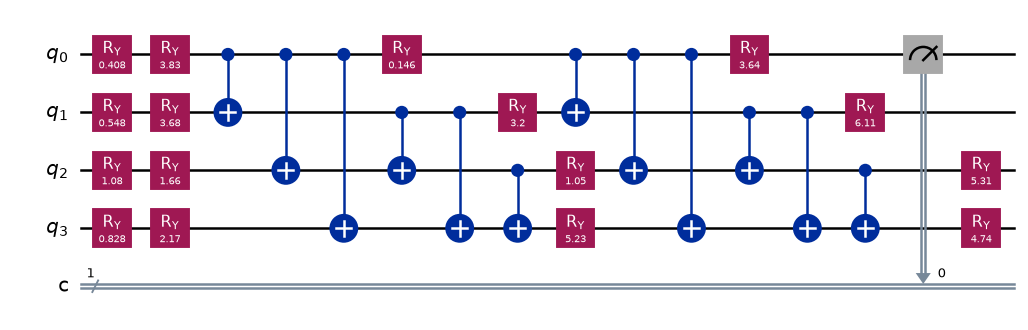

In [17]:
# ---- Circuit 1: one member classifier (encode e-mail -> trained ansatz -> measure Z on qubit 0) ----------------------------
from qiskit import ClassicalRegister
th_show = ENS[0]["thetas"][0]
bound1 = member_circuit.assign_parameters({**dict(zip(xs, A_te[0])), **dict(zip(ansatz.parameters, th_show))})
shown1 = bound1.copy(); shown1.add_register(ClassicalRegister(1, "c")); shown1.measure(0, 0)
print("Circuit 1 (member classifier C_j = V^dagger Z0 V): qubits =", shown1.num_qubits, "| depth =", shown1.depth(),
      "| trainable parameters =", N_PARAMS, "| data-encoding angles =", N_QUBITS, "| two-qubit gates =", shown1.num_nonlocal_gates())
fig_ = shown1.draw("mpl", fold=-1); display(fig_); plt.close(fig_)

Circuit 2 (quantum bagging read-out): qubits = 10 | depth (boxes count as one layer) = 9 | trainable parameters = 0 (the 31 member circuits are encoded in the controlled-U boxes; 372 angles in total)


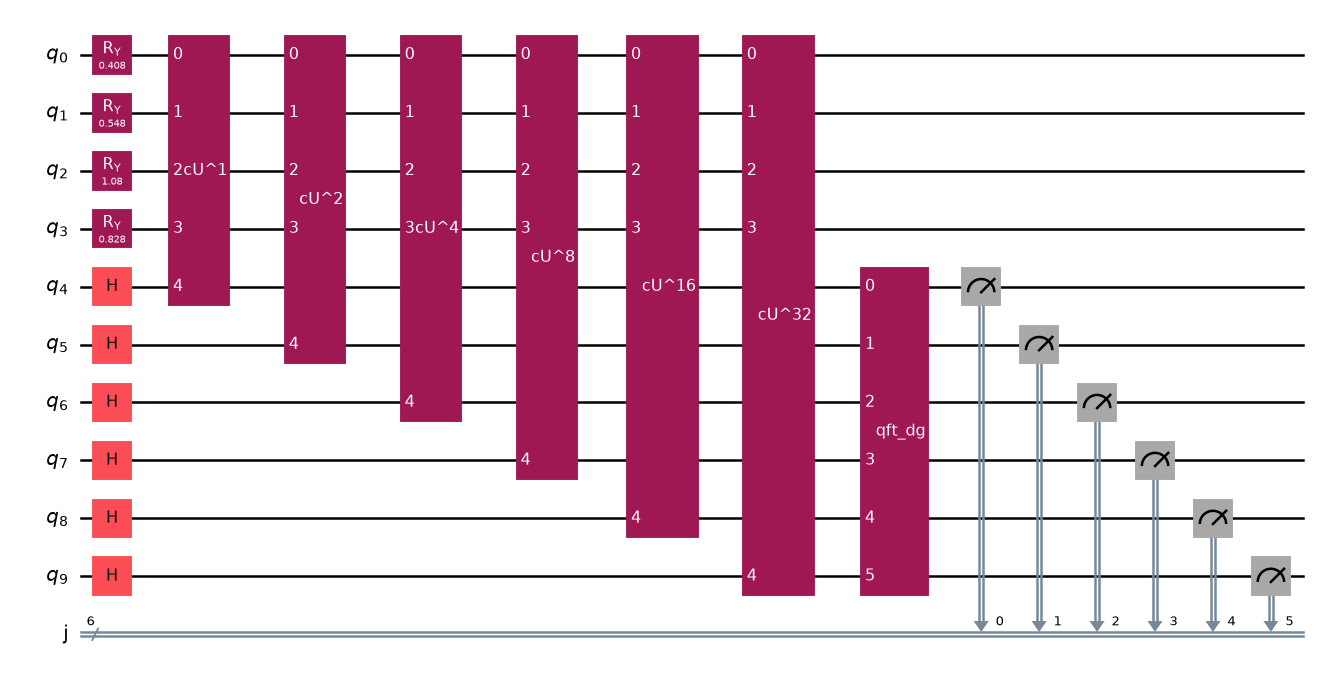

In [18]:
# ---- Circuit 2: phase estimation of exp(-i (pi/2) C) on a real test e-mail (Definition 6) -----------------------------------
qpe_demo = qpe_circuit(C_bag, A_te[0], QPE_BITS)
shown2 = qpe_demo.copy(); shown2.add_register(ClassicalRegister(QPE_BITS, "j")); shown2.measure(range(N_QUBITS, N_QUBITS + QPE_BITS), range(QPE_BITS))
print("Circuit 2 (quantum bagging read-out): qubits =", shown2.num_qubits, "| depth (boxes count as one layer) =", shown2.depth(),
      "| trainable parameters = 0 (the %d member circuits are encoded in the controlled-U boxes; %d angles in total)" % (N_MEMBERS, N_MEMBERS * N_PARAMS))
fig_ = shown2.draw("mpl", fold=40); display(fig_); plt.close(fig_)

Circuit 3 verified: P(measure 0) = cos^2(P t / 2) for P = 0.75, t = 1, 2, 3 (Lemma 11 proof).
Circuit 3 (one protocol query): qubits = 4 | depth = 10 | trainable parameters = 0 (rotation angles are the participants' data) | two-qubit gates = 6


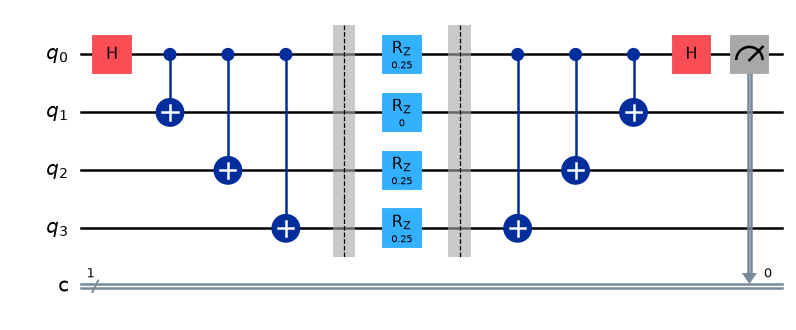

In [19]:
# ---- Circuit 3: one query of the private k-means protocol (Section V) for N = 4 participants --------------------------------
def protocol_circuit(deltas, t=1, measure=False):
    """Experimenter prepares (|0>^N+|1>^N)/sqrt2; participant j applies exp(-i Z delta_j/(2N)) = RZ(delta_j/N) (t times);
    the experimenter undoes the GHZ entanglement with N-1 CNOTs, applies H and measures qubit 0 (Lemma 11)."""
    N = len(deltas); qc = QuantumCircuit(N, 1 if measure else 0)
    qc.h(0)
    for j in range(1, N): qc.cx(0, j)
    qc.barrier()
    for _ in range(t):
        for j in range(N): qc.rz(deltas[j] / N, j)
    qc.barrier()
    for j in range(N - 1, 0, -1): qc.cx(0, j)
    qc.h(0)
    if measure: qc.measure(0, 0)
    return qc

demo_deltas = [1, 0, 1, 1]                      # participants 0, 2, 3 are closest to this cluster; participant 1 is not
P_demo = sum(demo_deltas) / len(demo_deltas)
for t in (1, 2, 3):
    p0 = Statevector(protocol_circuit(demo_deltas, t)).probabilities([0])[0]
    assert abs(p0 - np.cos(P_demo * t / 2) ** 2) < 1e-12, (t, p0)
print(f"Circuit 3 verified: P(measure 0) = cos^2(P t / 2) for P = {P_demo}, t = 1, 2, 3 (Lemma 11 proof).")
c3 = protocol_circuit(demo_deltas, 1, measure=True)
print("Circuit 3 (one protocol query): qubits =", c3.num_qubits, "| depth =", c3.depth(), "| trainable parameters = 0 (rotation angles are the participants' data) | two-qubit gates =", c3.num_nonlocal_gates())
fig_ = c3.draw("mpl"); display(fig_); plt.close(fig_)

Circuit 4 verified: success probability of the symmetric Helstrom attack = 1/2 + (1/2) sin(q/2N) for five (q, N) pairs
Circuit 4 (membership attack, q=4, N=20): qubits = 4 | depth = 12 | trainable parameters = 0 | two-qubit gates = 6


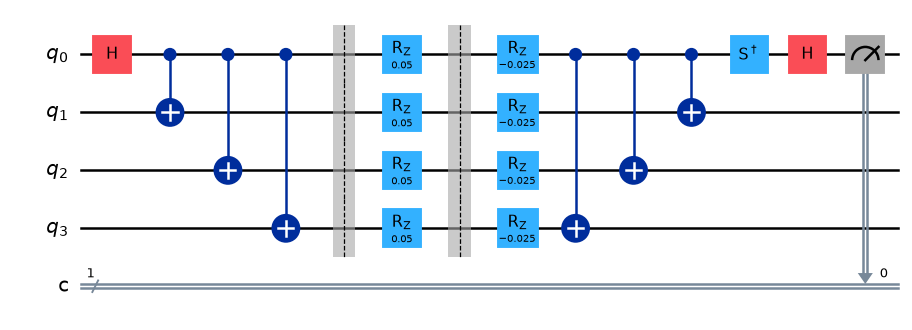

In [20]:
# ---- Circuit 4: the eavesdropper's optimal membership test (Theorem 12) for q = 4 rotations -----------------------------------
def attack_circuit(q, N, participate, measure=False):
    """E sends B a GHZ state on q qubits; B applies exp(-iZ/2N) to each qubit if he participates; E undoes half of the rotation
    (symmetric Helstrom probe), decodes the GHZ state and measures in the Y basis to tell the two cases apart."""
    qc = QuantumCircuit(q, 1 if measure else 0)
    qc.h(0)
    for j in range(1, q): qc.cx(0, j)
    qc.barrier()
    if participate:
        for j in range(q): qc.rz(1.0 / N, j)                    # B's action: exp(-iZ/(2N)) on each of the q qubits
    qc.barrier()
    for j in range(q): qc.rz(-0.5 / N, j)                       # E: half-angle counter-rotation
    for j in range(q - 1, 0, -1): qc.cx(0, j)
    qc.sdg(0); qc.h(0)                                          # Y-basis read-out
    if measure: qc.measure(0, 0)
    return qc

def attack_success(q, N):
    p_part = Statevector(attack_circuit(q, N, True)).probabilities([0]); p_not = Statevector(attack_circuit(q, N, False)).probabilities([0])
    o = int(np.argmax([p_part[0], p_part[1]]))                  # E guesses "participated" when it sees the outcome that is likelier then
    return 0.5 * (p_part[o] + 1 - p_not[o])

for q_, N_ in [(2, 10), (4, 20), (6, 40), (8, 25), (10, 50)]:
    s_circ, s_theory = attack_success(q_, N_), 0.5 + 0.5 * np.sin(q_ / (2 * N_))
    assert abs(s_circ - s_theory) < 1e-12, (q_, N_, s_circ, s_theory)
print("Circuit 4 verified: success probability of the symmetric Helstrom attack = 1/2 + (1/2) sin(q/2N) for five (q, N) pairs")
c4 = attack_circuit(4, 20, True, measure=True)
print("Circuit 4 (membership attack, q=4, N=20): qubits =", c4.num_qubits, "| depth =", c4.depth(), "| trainable parameters = 0 | two-qubit gates =", c4.num_nonlocal_gates())
fig_ = c4.draw("mpl"); display(fig_); plt.close(fig_)

## 7. Threat Model 2: an adversary who controls a fraction alpha of the classifiers

Threat Model 2 gives the adversary *complete knowledge* of the test state, of all classifiers and of the training data, and
unbounded computing power. It replaces a of the M members by Hermitian unitaries C'_j of its choice (so alpha = a/M of the
weight). We attack the real ensemble `ENS[0]` of section 5 with three read-outs:

* **sign of the mean** sign<psi|C|psi> (the strawman of Eq. 8),
* **eigenspace projection** of Definition 6 (the paper's proposal),
* **majority vote** of the member labels (classical bagging); the optimal attacker simply flips correct voters, so its
  breaking point is exact.

For the first two the adversary uses its best C'. The *reflection attack* C' = s(2|psi><psi| - 1) gives <psi|C'|psi> = s,
which is the largest possible effect on the mean. The *optimised attack* starts from the reflection and hill-climbs over
Hermitian unitaries (sign of a perturbed Hermitian matrix) to push the probability P(+) of the eigenspace read-out to the wrong
side. For every correctly classified test e-mail we record the **smallest number of compromised members that flips the class**.
At the same time the notebook checks the paper's perturbation statements: ||C' - C||_2 <= 2 alpha (Eq. 10), every eigenvalue
moves by at most 2 alpha (A32), and Corollary 10: no flip is possible while alpha < gamma/4, where gamma/2 is the smallest
|eigenvalue| of C in the support of the test state.

**Why Corollary 10 deserves a separate look.** Its proof shows that no eigenvalue of C changes sign while alpha < gamma/4
(Weyl's inequality), and concludes that the class cannot change. But the class is not decided by the signs of the eigenvalues
alone: it is decided by how much of the test state lies in the positive eigenspace, and *that eigenspace rotates* when C is
perturbed. The notebook therefore (i) checks the eigenvalue-sign statement, (ii) checks the corollary's conclusion directly
against attacks, and (iii) tests a **margin-aware certificate that we derive here** (it is not in the paper): with
g = gamma/2, a perturbation of norm at most 2 alpha < g moves the projector onto the positive eigenspace by at most
alpha/(g - 2 alpha) in operator norm (resolvent argument on the imaginary axis), so the class of a test state with clean margin
m = |P(+) - 1/2| cannot change while alpha < m g/(1 + 2m).

258 of 300 test e-mails are classified correctly by all three read-outs; attacking 150 of them


attacks finished in 45.1 s


,read-out,median members needed to flip,min,flipped by 1 member (%),flipped by 3 members (%)
0,sign of the mean (Eq. 8),6.0,1,10.00,26.67
1,majority vote (classical bagging),16.0,3,0.00,1.33
2,"eigenspace projection, reflection attack",6.0,1,8.67,22.67
3,"eigenspace projection, strongest attack found",6.0,1,8.67,22.67


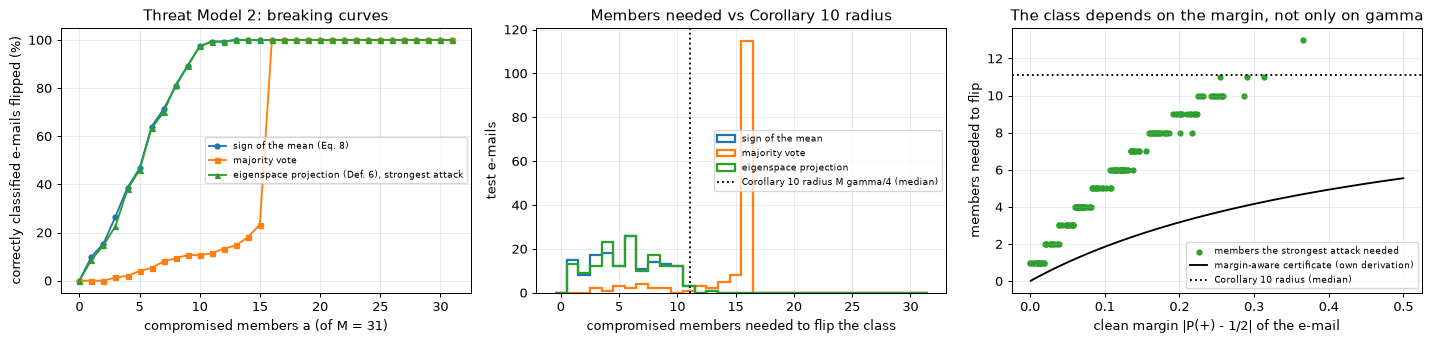

Eq. (10): max ||C' - C||_2 / (2 alpha) over 1560 attacked ensembles = 1.000  (must be <= 1)
(A32)   : max (largest eigenvalue shift) / (2 alpha)                      = 0.995  (must be <= 1)
paper's argument: no eigenvalue of C changes sign while a/M < gamma/4 -> unchanged in 1650 of 1650 reflection attacks (must be all)
Corollary 10 as stated (class cannot change while a/M < gamma/4): the class was flipped for 149 of 150 attacked e-mails
certificate is non-vacuous (certifies >= 1 compromised member) for 100 % of the attacked e-mails; median certified members = 11, median gamma = 1.431
margin-aware certificate (a/M < m g/(1+2m), m = clean margin, g = gamma/2): violated for 0 (strongest attack) / 0 (reflection) of 150 e-mails; certifies >= 1 member for 82 % (median 2)


In [21]:
def herm_unitary(H):
    """Hermitian unitary with eigenvalues +/-1: the sign function of a Hermitian matrix (every such C' is an allowed classifier)."""
    w, V = np.linalg.eigh(H); return (V * np.where(w >= 0, 1.0, -1.0)) @ V.conj().T

def reflection(psi, s): return s * (2 * np.outer(psi, psi.conj()) - np.eye(DIM))

def pplus_one(C, psi):
    w, V = np.linalg.eigh(C); return float((np.abs(V.conj().T @ psi) ** 2)[w > 0].sum())

def rand_herm(r, scale):
    G = r.standard_normal((DIM, DIM)) + 1j * r.standard_normal((DIM, DIM)); return scale * (G + G.conj().T) / 2

def min_compromised(Cs, psi, y_pm, steps, r):
    """Smallest number of replaced members a that flips the class, per read-out. y_pm = +1 (spam) / -1 (not spam)."""
    M = len(Cs); ex = np.array([psi @ C @ psi for C in Cs]).real
    order = np.argsort(-y_pm * ex)                          # replace the members that help the true class most
    out = dict(expectation=None, majority=None, eigen_reflection=None, eigen_optimised=None)
    checks = []                                              # (a, ||dC||_2, max eigenvalue shift) for Eq. (10) and (A32)
    C_full = Cs.mean(0); w_full = np.linalg.eigvalsh(C_full); n_pos = int(np.sum(w_full > 0))
    sign_checks = []                                         # does every eigenvalue keep its sign while a/M < gamma/4 ? (the paper's argument)
    for a in range(1, int(np.ceil(M * 2 * np.abs(w_full).min() / 4))):
        Ca = (Cs[order[a:]].sum(0) + a * reflection(psi, -y_pm)) / M
        sign_checks.append(int(np.sum(np.linalg.eigvalsh(Ca) > 0)) == n_pos)
    for a in range(1, M + 1):                                # sign of the mean and majority vote
        if out["expectation"] is None and y_pm * (ex[order[a:]].sum() - a * y_pm) / M <= 0: out["expectation"] = a
    k_correct = int(np.sum(y_pm * ex > 0))
    out["majority"] = max(1, k_correct - M // 2)
    honest = lambda a: Cs[order[a:]].sum(0)                  # members that stay honest when a are replaced
    for a in range(1, M + 1):                                # reflection attack on the eigenspace read-out
        Ca = (honest(a) + a * reflection(psi, -y_pm)) / M
        w_a = np.linalg.eigvalsh(Ca)
        checks.append((a, np.linalg.norm(Ca - C_full, 2) / (2 * a / M), np.max(np.abs(w_a - w_full)) / (2 * a / M)))
        if y_pm * (pplus_one(Ca, psi) - 0.5) <= 0: out["eigen_reflection"] = a; break
    if out["eigen_reflection"] is None: out["eigen_reflection"] = M + 1
    out["eigen_optimised"] = out["eigen_reflection"]
    for a in range(1, out["eigen_reflection"]):              # can a cleverer C' break it with fewer members?
        Hbest = reflection(psi, -y_pm); best_f, sigma = -1e9, 0.5       # start from the reflection attack
        for st in range(steps):
            Hn = Hbest if st == 0 else Hbest + rand_herm(r, sigma)
            Cn = herm_unitary(Hn); Ca = (honest(a) + a * Cn) / M; f = -y_pm * (pplus_one(Ca, psi) - 0.5)
            if f > best_f: best_f, Hbest = f, Hn; Cb = Cn
            sigma *= 0.96
        Ca = (honest(a) + a * Cb) / M; w_a = np.linalg.eigvalsh(Ca)
        checks.append((a, np.linalg.norm(Ca - C_full, 2) / (2 * a / M), np.max(np.abs(w_a - w_full)) / (2 * a / M)))
        if best_f >= 0: out["eigen_optimised"] = a; break
    out["sign_checks_ok"] = int(sum(sign_checks)); out["sign_checks_n"] = len(sign_checks)
    return out, checks

# Which test e-mails does every read-out classify correctly with no attack?  Those are attacked.
Cs0 = ENS[0]["C"]; Cbar = Cs0.mean(0); y_pm_te = 2 * y_te - 1
d0 = decisions(ENS[0], S_te)
ok = np.where((d0["expectation"] == y_te) & (d0["eigen"] == y_te) & (d0["majority"] == y_te))[0]
ra = np.random.default_rng(SEED + 7)
chosen = ra.choice(ok, min(N_ATTACK_STATES, len(ok)), replace=False)
print(f"{len(ok)} of {len(y_te)} test e-mails are classified correctly by all three read-outs; attacking {len(chosen)} of them")
t0 = time.time(); rows, checks_all = [], []
w_c, V_c = np.linalg.eigh(Cbar)
for i in chosen:
    psi = S_te[i].astype(complex); o, ch = min_compromised(Cs0, psi, y_pm_te[i], ATTACK_STEPS, ra)
    c2 = np.abs(V_c.conj().T @ psi) ** 2; gamma = 2 * np.abs(w_c[c2 > 1e-12]).min()
    o["gamma"] = gamma; o["a_cert"] = int(np.ceil(N_MEMBERS * gamma / 4) - 1); o["i"] = i
    margin = y_pm_te[i] * (pplus_one(Cbar, psi) - 0.5); g_half = gamma / 2                    # clean margin |P(+) - 1/2| of this e-mail
    o["margin"] = margin                                                                       # margin-aware certificate (own derivation, below)
    o["a_cert2"] = max(0, int(np.ceil(N_MEMBERS * margin * g_half / (1 + 2 * margin)) - 1))
    rows.append(o); checks_all += ch
print(f"attacks finished in {time.time()-t0:.1f} s")
ATT = pd.DataFrame(rows)
M_ = N_MEMBERS
summary = pd.DataFrame({
    "read-out": ["sign of the mean (Eq. 8)", "majority vote (classical bagging)", "eigenspace projection, reflection attack", "eigenspace projection, strongest attack found"],
    "median members needed to flip": [ATT.expectation.median(), ATT.majority.median(), ATT.eigen_reflection.median(), ATT.eigen_optimised.median()],
    "min": [ATT.expectation.min(), ATT.majority.min(), ATT.eigen_reflection.min(), ATT.eigen_optimised.min()],
    "flipped by 1 member (%)": [100 * (ATT[c] <= 1).mean() for c in ["expectation", "majority", "eigen_reflection", "eigen_optimised"]],
    "flipped by 3 members (%)": [100 * (ATT[c] <= 3).mean() for c in ["expectation", "majority", "eigen_reflection", "eigen_optimised"]],
})
display(summary.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
aa = np.arange(0, M_ + 1)
for col, lab, st in [("expectation", "sign of the mean (Eq. 8)", "o-"), ("majority", "majority vote", "s-"), ("eigen_optimised", "eigenspace projection (Def. 6), strongest attack", "^-")]:
    ax[0].plot(aa, [100 * (ATT[col] <= a).mean() for a in aa], st, label=lab, ms=4)
ax[0].set_xlabel("compromised members a (of M = %d)" % M_); ax[0].set_ylabel("correctly classified e-mails flipped (%)")
ax[0].set_title("Threat Model 2: breaking curves"); ax[0].legend(fontsize=7)
bins = np.arange(0, M_ + 2) - 0.5
for col, lab, c_ in [("expectation", "sign of the mean", "#1f77b4"), ("majority", "majority vote", "#ff7f0e"), ("eigen_optimised", "eigenspace projection", "#2ca02c")]:
    ax[1].hist(ATT[col], bins=bins, histtype="step", lw=1.8, color=c_, label=lab)
ax[1].axvline(np.median(ATT.gamma / 4 * M_), c="k", ls=":", label="Corollary 10 radius M gamma/4 (median)")
ax[1].set_xlabel("compromised members needed to flip the class"); ax[1].set_ylabel("test e-mails"); ax[1].set_title("Members needed vs Corollary 10 radius"); ax[1].legend(fontsize=7)
ax[2].scatter(ATT.margin, ATT.eigen_optimised, c="#2ca02c", s=16, label="members the strongest attack needed")
mm_ = np.linspace(0.001, max(0.5, ATT.margin.max()), 100); g_half0 = ATT.gamma.median() / 2
ax[2].plot(mm_, M_ * mm_ * g_half0 / (1 + 2 * mm_), "k-", label="margin-aware certificate (own derivation)")
ax[2].axhline(np.median(ATT.gamma / 4 * M_), c="k", ls=":", label="Corollary 10 radius (median)")
ax[2].set_xlabel("clean margin |P(+) - 1/2| of the e-mail"); ax[2].set_ylabel("members needed to flip"); ax[2].set_title("The class depends on the margin, not only on gamma"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

chk = np.array(checks_all)
EQ10_RATIO, A32_RATIO = float(chk[:, 1].max()), float(chk[:, 2].max())
viol = int(np.sum(ATT.eigen_optimised <= ATT.a_cert))
viol2 = int(np.sum(ATT.eigen_optimised <= ATT.a_cert2)); viol2r = int(np.sum(ATT.eigen_reflection <= ATT.a_cert2))
SIGN_OK, SIGN_N = int(ATT.sign_checks_ok.sum()), int(ATT.sign_checks_n.sum())
print(f"Eq. (10): max ||C' - C||_2 / (2 alpha) over {len(chk)} attacked ensembles = {EQ10_RATIO:.3f}  (must be <= 1)")
print(f"(A32)   : max (largest eigenvalue shift) / (2 alpha)                      = {A32_RATIO:.3f}  (must be <= 1)")
print(f"paper's argument: no eigenvalue of C changes sign while a/M < gamma/4 -> unchanged in {SIGN_OK} of {SIGN_N} reflection attacks (must be all)")
print(f"Corollary 10 as stated (class cannot change while a/M < gamma/4): the class was flipped for {viol} of {len(ATT)} attacked e-mails")
print(f"certificate is non-vacuous (certifies >= 1 compromised member) for {100*(ATT.a_cert>=1).mean():.0f} % of the attacked e-mails; "
      f"median certified members = {ATT.a_cert.median():.0f}, median gamma = {ATT.gamma.median():.3f}")
print(f"margin-aware certificate (a/M < m g/(1+2m), m = clean margin, g = gamma/2): violated for {viol2} (strongest attack) / {viol2r} (reflection) of {len(ATT)} e-mails; "
      f"certifies >= 1 member for {100*(ATT.a_cert2>=1).mean():.0f} % (median {ATT.a_cert2.median():.0f})")
EQ8_FLIP1 = float((ATT.expectation <= 1).mean()); EIG_FLIP1 = float((ATT.eigen_optimised <= 1).mean())
MED_EXP, MED_EIG, MED_MAJ = float(ATT.expectation.median()), float(ATT.eigen_optimised.median()), float(ATT.majority.median())
CERT_NONVAC = float((ATT.a_cert >= 1).mean()); COR10_VIOL = viol; COR10_FLIPPED = float((ATT.eigen_optimised <= ATT.a_cert).mean())
CERT2_VIOL, CERT2_NONVAC = viol2, float((ATT.a_cert2 >= 1).mean())

In [22]:
# How large must the ensemble be before Corollary 10 certifies anything? (spectral gap of C for growing sub-ensembles)
rows = []
for Mp in sorted(set([3, 5, 9, 15, N_MEMBERS])):
    if Mp > N_MEMBERS: continue
    E_ = np.linalg.eigvalsh(Cs0[:Mp].mean(0)); gam = 2 * np.abs(E_).min()
    rows.append(dict(M=Mp, min_abs_eigenvalue=np.abs(E_).min(), gamma=gam, certified_fraction_gamma_over_4=gam / 4, certified_members=Mp * gam / 4, one_member_is_alpha=1 / Mp))
GAP = pd.DataFrame(rows); display(GAP.round(3))

,M,min_abs_eigenvalue,gamma,certified_fraction_gamma_over_4,certified_members,one_member_is_alpha
0,3,0.822,1.644,0.411,1.233,0.333
1,5,0.807,1.614,0.403,2.017,0.200
2,9,0.653,1.305,0.326,2.937,0.111
3,15,0.726,1.451,0.363,5.442,0.067
4,31,0.716,1.431,0.358,11.090,0.032


## 8. Causative attacks: poisoning the training labels

Section II of the paper says bagging "limits the impact of an adversary that controls a small fraction of the data set". We test
that with the attack the paper's introduction worries about, **false negatives**: the adversary flips the label of a fraction
eta of the *spam* training e-mails to "not spam", so that spam is learnt as normal. Each model is retrained on the poisoned
training set and judged on the clean test set by accuracy and by spam recall (the share of spam that is caught). Compared are
the single VQC, the quantum bag (two read-outs), SVC and the bagged SVC. Mean +/- std over `N_REPEATS` repetitions.

poisoning study finished in 654.3 s


,accuracy @ eta=0.0,accuracy @ eta=0.2,accuracy @ eta=0.4,recall @ eta=0.0,recall @ eta=0.2,recall @ eta=0.4
model,,,,,,
bagged SVC,88.3,85.3,75.4,86.1,76.5,51.9
quantum bag: eigenspace projection,88.2,74.4,58.9,84.0,49.5,18.0
quantum bag: sign of mean,88.4,74.3,58.1,84.9,49.3,16.1
single SVC,88.0,85.4,74.3,86.0,76.5,49.5
single VQC,87.3,74.7,58.7,83.7,50.1,17.6


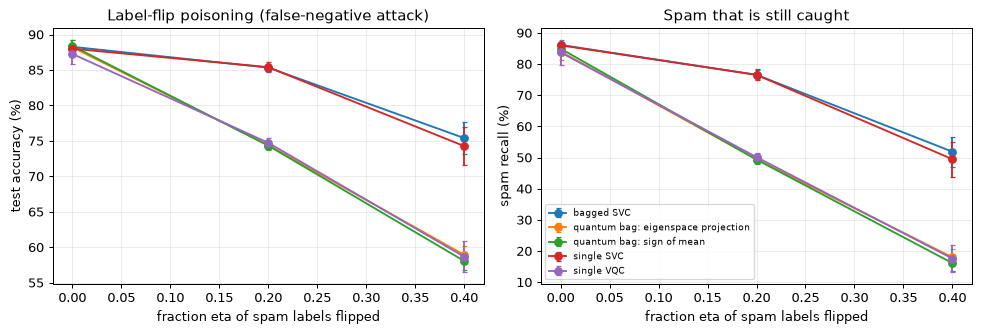

spam-recall drop at eta=0.4: single VQC 66.1 pts | quantum bag 66.0 pts | single SVC 36.5 pts | bagged SVC 34.3 pts


In [23]:
def poison_spam_labels(y01, eta, seed):
    yp = y01.copy(); r = np.random.default_rng(seed); sp = np.where(yp == 1)[0]
    yp[r.choice(sp, int(round(eta * len(sp))), replace=False)] = 0; return yp

rec = lambda pred, y: float(np.mean(pred[y == 1]))
rows = []
t0 = time.time()
for eta in POISON_FRACTIONS:
    for r in range(N_REPEATS):
        yp = poison_spam_labels(y_tr, eta, SEED + 100 * r + int(1000 * eta))
        if eta == 0.0:                                   # the clean models of section 5 (same seeds): no need to train them again
            s1, bg = single[r], ENS[r]
        else:
            s1 = build_ensemble(S_tr, yp, 1, SEED + 10 * r, MAXITER, bootstrap=False)
            bg = build_ensemble(S_tr, yp, N_MEMBERS, SEED + 10 * r + 1, MAXITER)
        d1, db = decisions(s1, S_te), decisions(bg, S_te)
        svc = SVC(C=1.0).fit(A_tr, yp); bsvc = BaggingClassifier(SVC(C=1.0), n_estimators=N_MEMBERS, random_state=SEED + r).fit(A_tr, yp)
        for name, pred in [("single VQC", d1["expectation"]), ("quantum bag: eigenspace projection", db["eigen"]), ("quantum bag: sign of mean", db["expectation"]),
                           ("single SVC", svc.predict(A_te).astype(bool)), ("bagged SVC", bsvc.predict(A_te).astype(bool))]:
            rows.append(dict(eta=eta, rep=r, model=name, accuracy=acc_of(pred, y_te), spam_recall=rec(pred, y_te)))
print(f"poisoning study finished in {time.time()-t0:.1f} s")
PZ = pd.DataFrame(rows)
agg = PZ.groupby(["model", "eta"]).agg(acc=("accuracy", "mean"), acc_sd=("accuracy", "std"), rec=("spam_recall", "mean"), rec_sd=("spam_recall", "std")).reset_index()
show = agg.pivot(index="model", columns="eta", values="rec").mul(100).round(1); show.columns = [f"recall @ eta={c}" for c in show.columns]
show2 = agg.pivot(index="model", columns="eta", values="acc").mul(100).round(1); show2.columns = [f"accuracy @ eta={c}" for c in show2.columns]
display(pd.concat([show2, show], axis=1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m_ in agg.model.unique():
    s = agg[agg.model == m_]
    ax[0].errorbar(s.eta, 100 * s.acc, yerr=100 * s.acc_sd.fillna(0), marker="o", label=m_, capsize=2)
    ax[1].errorbar(s.eta, 100 * s.rec, yerr=100 * s.rec_sd.fillna(0), marker="o", label=m_, capsize=2)
ax[0].set_xlabel("fraction eta of spam labels flipped"); ax[0].set_ylabel("test accuracy (%)"); ax[0].set_title("Label-flip poisoning (false-negative attack)")
ax[1].set_xlabel("fraction eta of spam labels flipped"); ax[1].set_ylabel("spam recall (%)"); ax[1].set_title("Spam that is still caught"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
eta_max = max(POISON_FRACTIONS)
def rec_at(model, eta): return float(agg[(agg.model == model) & (agg.eta == eta)].rec.iloc[0])
POIS_DROP_SINGLE = rec_at("single VQC", 0.0) - rec_at("single VQC", eta_max)
POIS_DROP_BAG = rec_at("quantum bag: eigenspace projection", 0.0) - rec_at("quantum bag: eigenspace projection", eta_max)
POIS_DROP_SVC = rec_at("single SVC", 0.0) - rec_at("single SVC", eta_max)
POIS_DROP_BSVC = rec_at("bagged SVC", 0.0) - rec_at("bagged SVC", eta_max)
print(f"spam-recall drop at eta={eta_max}: single VQC {100*POIS_DROP_SINGLE:.1f} pts | quantum bag {100*POIS_DROP_BAG:.1f} pts | "
      f"single SVC {100*POIS_DROP_SVC:.1f} pts | bagged SVC {100*POIS_DROP_BSVC:.1f} pts")

## 9. Lemma 8 and Theorem 9: the cost of reading out the bag

Lemma 8 simulates e^{-iCt} for C = sum_j b_j C_j with the truncated-Taylor (linear combination of unitaries) method: it needs
r = O(t) segments, each with a Taylor expansion up to order K = O(log(t/eps)/log log(t/eps)), so the number of calls to the
programmable classifier oracle is O(t log(t/eps)/log log(t/eps)) **independently of the number M of classifiers**
(Theorem 9 then multiplies by the O(1/(delta eps)) repetitions of coherent phase estimation).

A classical computer cannot test the oracle-model complexity, but it can test the mathematics underneath: for the real
ensemble operator C we find the smallest Taylor order K for which the truncated series of a segment of length t/r (r =
ceil(t/ln 2), the usual choice for oblivious amplitude amplification) is within eps/r of e^{-iCt/r} in spectral norm, and we
compare r K with the paper's expression. We also check that K does not change when the ensemble gets bigger, and that the
phase-estimation register of section 6 uses 2^m - 1 applications of U for an eigenvalue resolution 4/2^m, i.e. O(1/eps).

,t,eps,segments_r,Taylor_order_K,calls_rK,paper_expression,ratio
0,1,0.01,2,3,6,3.015,1.990
1,1,0.00,2,5,10,4.148,2.411
2,1,0.00,2,7,14,5.261,2.661
3,1,0.00,2,8,16,6.323,2.531
4,4,0.01,6,4,24,13.386,1.793
5,4,0.00,6,6,36,17.956,2.005
6,4,0.00,6,8,48,22.344,2.148
7,4,0.00,6,10,60,26.533,2.261
8,16,0.01,24,5,120,59.067,2.032
9,16,0.00,24,7,168,77.201,2.176


calls r*K divided by t log(t/eps)/log log(t/eps): min 1.79, max 2.66 (spread 1.48x over 16 settings)
Taylor order K at t=1, eps=1e-6 for ensembles of size M: {3: 7, 7: 7, 31: 7} -> independent of M
phase-estimation register: U applications 2^m - 1 = [7, 15, 31, 63, 127] for eigenvalue resolutions [0.5, 0.25, 0.125, 0.0625, 0.03125]


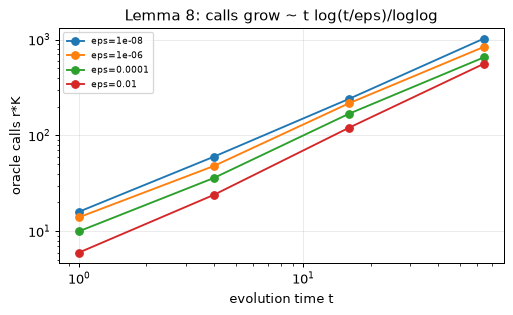

In [24]:
def taylor_order(Cm, tau, eps, kmax=80):
    exact = expm(-1j * tau * Cm); Mx = -1j * tau * Cm; term = np.eye(DIM, dtype=complex); S = term.copy()
    for K in range(kmax):
        if K > 0: term = term @ Mx / K; S = S + term
        if np.linalg.norm(exact - S, 2) <= eps: return K
    return kmax

rows = []
for t in (1, 4, 16, 64):
    for eps in (1e-2, 1e-4, 1e-6, 1e-8):
        r_ = int(np.ceil(t / np.log(2))); K = taylor_order(Cbar, t / r_, eps / r_)
        paper = t * np.log(t / eps) / np.log(np.log(t / eps))
        rows.append(dict(t=t, eps=eps, segments_r=r_, Taylor_order_K=K, calls_rK=r_ * K, paper_expression=paper, ratio=r_ * K / paper))
LEM8 = pd.DataFrame(rows); display(LEM8.round(3).head(16))
ratio_spread = float(LEM8.ratio.max() / LEM8.ratio.min())
print(f"calls r*K divided by t log(t/eps)/log log(t/eps): min {LEM8.ratio.min():.2f}, max {LEM8.ratio.max():.2f} (spread {ratio_spread:.2f}x over 16 settings)")
K_by_M = {Mp: taylor_order(Cs0[:Mp].mean(0), 1 / int(np.ceil(1 / np.log(2))), 1e-6 / int(np.ceil(1 / np.log(2)))) for Mp in (3, 7, N_MEMBERS)}
print("Taylor order K at t=1, eps=1e-6 for ensembles of size M:", K_by_M, "-> independent of M" if len(set(K_by_M.values())) <= 2 else "")
print("phase-estimation register: U applications 2^m - 1 =", [2 ** m - 1 for m in (3, 4, 5, 6, 7)], "for eigenvalue resolutions", [4 / 2 ** m for m in (3, 4, 5, 6, 7)])
fig, ax = plt.subplots(figsize=(5.8, 3.6))
for eps_ in sorted(LEM8.eps.unique()):
    s = LEM8[LEM8.eps == eps_]; ax.loglog(s.t, s.calls_rK, "o-", label=f"eps={eps_:g}")
ax.set_xlabel("evolution time t"); ax.set_ylabel("oracle calls r*K"); ax.set_title("Lemma 8: calls grow ~ t log(t/eps)/loglog"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 10. Section V: private quantum k-means

**Protocol (Threat Model 3).** N users hold private vectors x_j. The experimenter broadcasts k centroids and, for every
centroid, shares the GHZ-like state (|0>^N + |1>^N)/sqrt(2) over the users (one qubit each). A user whose vector is closest to
centroid p applies the tiny rotation exp(-iZ delta/(2N)) to the qubit of cluster p (delta = 1 to count membership, delta = the
q-th coordinate x_jq to accumulate coordinates) and sends the qubit back. The collective relative phase is the *sum*
sum_j delta_j / N, which phase estimation turns into P(f = p) (membership fraction) or into the unnormalised coordinate sum;
the ratio gives the new centroid. Circuit 3 above is one query of this protocol.

**What is checked.**
1. *Lemma 11* in practice: the simulated phase estimation (X and Y quadratures, t = 1, 2, 4, ... queries, `PE_SHOTS`
   shots each, grid maximum likelihood) recovers P and the centroids with an error that falls like 1/(total rotations).
2. *Theorem 12*: the best possible eavesdropper succeeds with probability 1/2 + (1/2) sin(q/2N) <= 1/2 + q/(4N)
   (q = rotations a participant makes). Verified by Circuit 4 (exact) and by a Monte-Carlo membership-inference attack.
3. *Utility versus privacy against a classical baseline*: Laplace local differential privacy at the same trace-distance
   (membership advantage), on the same real e-mails.
4. *Remark at the end of Section V*: a single malicious participant ruins the estimate; a median over groups repairs it
   (at a price in privacy).

The users here are the real e-mails of the training pool, each reduced to the same four principal components (fitted on the
training sample), standardised and clipped at +/-2 standard deviations, then mapped to [0, 1]^4 (the rotation angle must be at
most 1 so that all phases add up to at most one turn; plain min-max scaling would let a few outliers squeeze the bulk of the
e-mails so that k-means isolates the outliers instead of splitting the bulk). The pool is *not* the balanced training
sample of the classifiers: clustering is unsupervised and the experimenter never sees the labels, which are used only to report
cluster purity.

2947 users with 4 coordinates in [0,1]; spam share 0.40


,Q,total_t,rotations_per_user,mean_error,p95_error,error x rotations
0,2,3,120,0.06045,0.13946,7.25454
1,3,7,280,0.02843,0.06991,7.96056
2,4,15,600,0.01436,0.03606,8.61717
3,5,31,1240,0.00707,0.01758,8.77272
4,6,63,2520,0.00397,0.01000,10.00760
5,7,127,5080,0.00178,0.00449,9.05708
6,8,255,10200,0.00086,0.00221,8.75000


log-log slope of mean error vs rotations (Q >= 4): -0.99   (paper: error ~ 1/rotations, slope -1; independent shots would give -0.5)


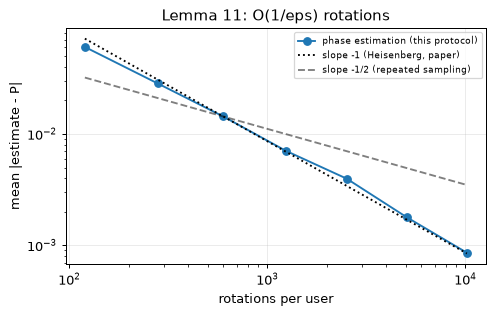

In [25]:
# ---- the users: real e-mails of the training pool, 4 principal components mapped to [0,1] (transforms fitted on the training sample) ---
sd_pc = Z_tr.std(0)                      # CHOICE: x = 0.5 + z/(4 sd) clipped to [0,1], i.e. +/-2 standard deviations of each principal component
X_part = np.clip(0.5 + pca.transform(scaler.transform(X_all[pool_tr])) / (4 * sd_pc), 0, 1)       # (min-max scaling would let a few outliers squeeze the bulk and k-means would isolate them)
y_part = y_all[pool_tr]; N_PART, D_PART = X_part.shape
print(f"{N_PART} users with {D_PART} coordinates in [0,1]; spam share {y_part.mean():.2f}")

GRID = np.linspace(0, 1, 20001)
QUAD = (lambda a: (1 + np.cos(a)) / 2, lambda a: (1 + np.sin(a)) / 2)      # P(outcome 0) in the X and the Y quadrature

def phase_estimate(phi, Q, shots, r, offset=0.0):
    """Estimate phi in [0,1] from t = 1, 2, ..., 2^(Q-1) queries (X and Y quadrature, `shots` each); returns (estimate, total t).
    `offset` is a phase added by a malicious participant on every query."""
    ll = np.zeros_like(GRID); tot = 0
    for q in range(Q):
        t = 2 ** q; tot += t
        for fn in QUAD:
            k0 = r.binomial(shots, np.clip(fn((phi + offset) * t), 0, 1))
            g = np.clip(fn(GRID * t), 1e-12, 1 - 1e-12)
            ll += k0 * np.log(g) + (shots - k0) * np.log(1 - g)
    return float(GRID[np.argmax(ll)]), tot

def rotations_per_estimate(Q, shots): return 2 * shots * (2 ** Q - 1)       # two quadratures; each shot at depth t costs t rotations

# ---- 1. Lemma 11: error of the phase estimate against the number of rotations a participant makes -------------------------------
rp = np.random.default_rng(SEED + 11); rows = []
for Q in range(2, 9):
    errs = []
    for _ in range(PE_TRIALS):
        phi = rp.uniform(0.02, 0.98); e, tot = phase_estimate(phi, Q, PE_SHOTS, rp); errs.append(abs(e - phi))
    rows.append(dict(Q=Q, total_t=tot, rotations_per_user=rotations_per_estimate(Q, PE_SHOTS), mean_error=np.mean(errs), p95_error=np.percentile(errs, 95)))
LEM11 = pd.DataFrame(rows); LEM11["error x rotations"] = LEM11.mean_error * LEM11.rotations_per_user
display(LEM11.round(5))
use = LEM11[LEM11.Q >= 4]
LEM11_SLOPE = float(np.polyfit(np.log(use.rotations_per_user), np.log(use.mean_error), 1)[0])
print(f"log-log slope of mean error vs rotations (Q >= 4): {LEM11_SLOPE:.2f}   (paper: error ~ 1/rotations, slope -1; independent shots would give -0.5)")
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.loglog(LEM11.rotations_per_user, LEM11.mean_error, "o-", label="phase estimation (this protocol)")
x0 = LEM11.rotations_per_user.values; ax.loglog(x0, LEM11.mean_error.iloc[2] * (x0[2] / x0), "k:", label="slope -1 (Heisenberg, paper)")
ax.loglog(x0, LEM11.mean_error.iloc[2] * np.sqrt(x0[2] / x0), "k--", alpha=0.5, label="slope -1/2 (repeated sampling)")
ax.set_xlabel("rotations per user"); ax.set_ylabel("mean |estimate - P|"); ax.set_title("Lemma 11: O(1/eps) rotations"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

In [26]:
# ---- 2. the protocol on the real users: R rounds of k-means, quantum protocol vs classical Lloyd from the same initial centroids -----------
def assign(X, mu): return np.argmin(((X[:, None, :] - mu[None]) ** 2).sum(2), axis=1)

def lloyd(X, mu, R):
    mu = mu.copy()
    for _ in range(R):
        a = assign(X, mu)
        for p in range(len(mu)):
            if np.any(a == p): mu[p] = X[a == p].mean(0)
    return mu

def quantum_round(X, mu, Q, shots, r, malicious_offset=0.0):
    N, d = X.shape; k = len(mu); a = assign(X, mu); new = mu.copy(); rot = 0
    for p in range(k):
        ind = (a == p).astype(float)
        P_hat, _ = phase_estimate(ind.sum() / N, Q, shots, r, malicious_offset); rot += rotations_per_estimate(Q, shots)
        if P_hat < 0.5 / N: continue
        for q in range(d):
            S_hat, _ = phase_estimate((X[:, q] * ind).sum() / N, Q, shots, r, malicious_offset)
            new[p, q] = min(1.0, S_hat / P_hat)
    return new, a, rot            # rotations counted for the user in cluster p: (1 + d) estimates per round

def quantum_kmeans(X, mu0, R, Q, shots, r):
    mu = mu0.copy(); rot_user = 0
    for _ in range(R):
        mu, a, _ = quantum_round(X, mu, Q, shots, r); rot_user += (1 + X.shape[1]) * rotations_per_estimate(Q, shots)
    return mu, rot_user

rk = np.random.default_rng(SEED + 12)
mu0 = np.full((K_CLUSTERS, D_PART), 0.5); mu0[:, 0] = np.linspace(0.25, 0.75, K_CLUSTERS)   # CHOICE: data-independent initial centroids spread along angle 1 (the experimenter knows no data)
mu_cl = lloyd(X_part, mu0, KMEANS_ROUNDS)
a_cl = assign(X_part, mu_cl)
purity = sum(max(np.sum((a_cl == p) & (y_part == 1)), np.sum((a_cl == p) & (y_part == 0))) for p in range(K_CLUSTERS)) / N_PART
print("classical Lloyd centroids after", KMEANS_ROUNDS, "rounds:\n", np.round(mu_cl, 3), f"\ncluster sizes {np.bincount(a_cl)}; purity w.r.t. spam / not spam {purity:.2f}")

SETTINGS = [(2, 2), (3, 2), (3, 5), (4, 5), (5, 5), (5, 10), (6, 10), (7, 10)]      # (Q, shots)
N_TRIALS_KM = 6 if FAST_MODE else 20
rows = []
for (Q, sh) in SETTINGS:
    errs = []
    for tr in range(N_TRIALS_KM):
        mu_q, rot_user = quantum_kmeans(X_part, mu0, KMEANS_ROUNDS, Q, sh, rk); errs.append(np.abs(mu_q - mu_cl).max())
    q_rot = rot_user
    theta = q_rot / (2 * N_PART); tv_q = float(np.sin(min(theta, np.pi / 2)))
    rows.append(dict(Q=Q, shots=sh, rotations_per_user_q=q_rot, centroid_error_Linf=np.mean(errs), TV_membership=tv_q,
                     eavesdropper_success=0.5 + 0.5 * tv_q, N_needed_for_advantage_0_05=int(np.ceil(q_rot / (2 * np.arcsin(0.1))))))
KM = pd.DataFrame(rows); display(KM.round(4))

classical Lloyd centroids after 3 rounds:
 [[0.316 0.603 0.436 0.504]
 [0.642 0.396 0.553 0.499]] 
cluster sizes [ 977 1970]; purity w.r.t. spam / not spam 0.88


,Q,shots,rotations_per_user_q,centroid_error_Linf,TV_membership,eavesdropper_success,N_needed_for_advantage_0_05
0,2,2,180,0.5867,0.0305,0.5153,899
1,3,2,420,0.5320,0.0712,0.5356,2097
2,3,5,1050,0.4724,0.1772,0.5886,5242
3,4,5,2250,0.2017,0.3725,0.6863,11232
4,5,5,4650,0.1146,0.7096,0.8548,23212
5,5,10,9300,0.0699,1.0000,1.0000,46423
6,6,10,18900,0.0382,1.0000,1.0000,94343
7,7,10,38100,0.0198,1.0000,1.0000,190182


,q,N,q_over_N,success_MonteCarlo,success_GHZ_probe_formula,optimum_over_all_probes,bound_1_2_plus_q_over_4N,z_score
0,10,200,0.05,0.5114,0.5125,0.5125,0.5125,-0.9961
1,40,200,0.20,0.5503,0.5499,0.5499,0.5500,0.3205
2,100,200,0.50,0.6230,0.6237,0.6237,0.6250,-0.6681
3,200,200,1.00,0.7388,0.7397,0.7397,0.7500,-0.7806
4,400,200,2.00,0.9207,0.9207,0.9207,1.0000,-0.0496
5,800,200,4.00,0.9556,0.9546,1.0000,1.0000,0.8732


q=4, N=20: advantage of GHZ probe 0.04992; best of 2000 random probes 0.03645; hill-climbed probe 0.04912; theory (1/2) sin(q/2N) = 0.04992


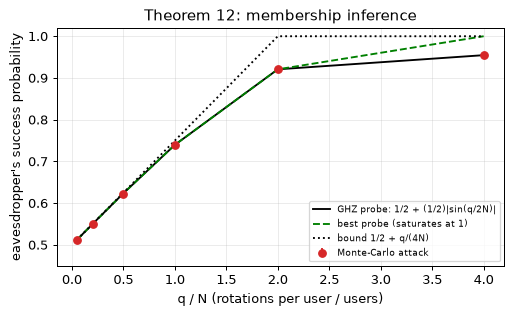

In [27]:
# ---- 3. Theorem 12: the eavesdropper's membership guess ---------------------------------------------------------------------------
sgn = 1.0 if Statevector(attack_circuit(2, 10, True)).probabilities([0])[0] > 0.5 else -1.0      # read-out convention, from the circuit
for q_, N_ in [(2, 10), (4, 20), (8, 25)]:
    p0 = Statevector(attack_circuit(q_, N_, True)).probabilities([0])[0]
    assert abs(p0 - (1 + sgn * np.sin(q_ / (2 * N_))) / 2) < 1e-12                               # closed form == circuit

rm = np.random.default_rng(SEED + 13); N_MC = 200
rows = []
for q_ in (10, 40, 100, 200, 400, 800):
    th = q_ / (2 * N_MC); p0_part = (1 + sgn * np.sin(th)) / 2; p0_not = (1 - sgn * np.sin(th)) / 2
    member = rm.random(MC_TRIALS) < 0.5                                                           # prior 1/2: B participates or not
    out0 = rm.random(MC_TRIALS) < np.where(member, p0_part, p0_not)                               # outcome of E's measurement
    guess_member = out0 if sgn > 0 else ~out0
    succ = float(np.mean(guess_member == member)); ghz_formula = 0.5 + 0.5 * abs(np.sin(th))
    rows.append(dict(q=q_, N=N_MC, q_over_N=q_ / N_MC, success_MonteCarlo=succ, success_GHZ_probe_formula=ghz_formula,
                     optimum_over_all_probes=0.5 + 0.5 * np.sin(min(th, np.pi / 2)), bound_1_2_plus_q_over_4N=min(1.0, 0.5 + q_ / (4 * N_MC)),
                     z_score=(succ - ghz_formula) / np.sqrt(0.25 / MC_TRIALS)))
T12 = pd.DataFrame(rows); display(T12.round(4))
T12_MC_OK = bool((T12.z_score.abs() < 4).all()); T12_BOUND_OK = bool((T12.optimum_over_all_probes <= T12.bound_1_2_plus_q_over_4N + 1e-12).all())

# no probe state does better than the GHZ state (q = 4): random pure probes and a hill climb
def trace_adv(psi, q, N):
    ph = np.exp(-1j * np.array([(q - 2 * bin(i).count("1")) / (2 * N) for i in range(2 ** q)]))      # U = exp(-i sum Z /(2N)) is diagonal
    f = abs(np.vdot(psi, ph * psi)) ** 2; return 0.5 * np.sqrt(max(0.0, 1 - f))
q_t, N_t = 4, 20; best_rand = 0.0
for _ in range(2000):
    v = rm.standard_normal(2 ** q_t) + 1j * rm.standard_normal(2 ** q_t); best_rand = max(best_rand, trace_adv(v / np.linalg.norm(v), q_t, N_t))
v = rm.standard_normal(2 ** q_t) + 1j * rm.standard_normal(2 ** q_t); v /= np.linalg.norm(v); bv = trace_adv(v, q_t, N_t)
for _ in range(3000):
    w_ = v + 0.05 * (rm.standard_normal(2 ** q_t) + 1j * rm.standard_normal(2 ** q_t)); w_ /= np.linalg.norm(w_)
    if trace_adv(w_, q_t, N_t) > bv: v, bv = w_, trace_adv(w_, q_t, N_t)
ghz = np.zeros(2 ** q_t, complex); ghz[0] = ghz[-1] = 1 / np.sqrt(2)
print(f"q=4, N=20: advantage of GHZ probe {trace_adv(ghz, q_t, N_t):.5f}; best of 2000 random probes {best_rand:.5f}; hill-climbed probe {bv:.5f}; "
      f"theory (1/2) sin(q/2N) = {0.5*np.sin(q_t/(2*N_t)):.5f}")
GHZ_OPTIMAL = bool(bv <= trace_adv(ghz, q_t, N_t) + 1e-9)

fig, ax = plt.subplots(figsize=(5.8, 3.6))
ax.plot(T12.q_over_N, T12.success_GHZ_probe_formula, "k-", label="GHZ probe: 1/2 + (1/2)|sin(q/2N)|"); ax.plot(T12.q_over_N, T12.optimum_over_all_probes, "g--", label="best probe (saturates at 1)"); ax.plot(T12.q_over_N, T12.bound_1_2_plus_q_over_4N, "k:", label="bound 1/2 + q/(4N)")
ax.errorbar(T12.q_over_N, T12.success_MonteCarlo, yerr=1 / np.sqrt(4 * MC_TRIALS) * 2, fmt="o", c="#d62728", label="Monte-Carlo attack")
ax.set_xlabel("q / N (rotations per user / users)"); ax.set_ylabel("eavesdropper's success probability"); ax.set_ylim(0.45, 1.02)
ax.set_title("Theorem 12: membership inference"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

,TV_membership,laplace_scale_b,centroid_error_Linf
0,0.02,374.9500,0.6267
1,0.05,149.8749,0.6110
2,0.10,74.7493,0.6426
3,0.20,36.9946,0.6371
4,0.30,24.2311,0.6384
5,0.50,13.6536,0.6047
6,0.70,8.6475,0.6097
7,0.90,5.0943,0.5581


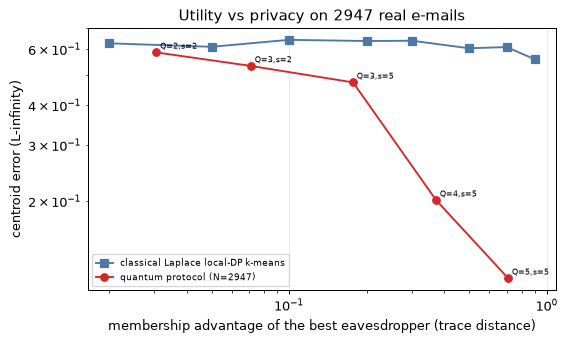

3 of 8 quantum settings leak completely at N = 2947 (q/2N >= pi/2).


,Q,shots,TV_membership,centroid_error_Linf,Laplace_LDP_error_at_same_TV,quantum_better
0,2,2,0.0305,0.5867,0.6194,True
1,3,2,0.0712,0.5320,0.6269,True
2,3,5,0.1772,0.4724,0.6380,True
3,4,5,0.3725,0.2017,0.6239,True
4,5,5,0.7096,0.1146,0.6068,True


at equal membership advantage (settings with 0.1 <= TV < 1) the quantum protocol has the smaller centroid error in 3 of 3 settings


In [28]:
# ---- 4. utility versus privacy: the quantum protocol against Laplace local differential privacy at the same trace distance ----------
def ldp_kmeans(X, mu0, R, b_round, r):
    mu = mu0.copy(); N, d = X.shape; k = len(mu)
    for _ in range(R):
        a = assign(X, mu); onehot = np.eye(k)[a]                              # (N, k)
        noise_cnt = r.laplace(0, b_round, size=(N, k)).sum(0); P_hat = (onehot.sum(0) + noise_cnt) / N
        new = mu.copy()
        for p in range(k):
            S_hat = ((X * onehot[:, [p]]).sum(0) + r.laplace(0, b_round, size=(N, d)).sum(0)) / N
            if P_hat[p] > 0.5 / N: new[p] = np.clip(S_hat / P_hat[p], 0, 1)
        mu = new
    return mu

rows = []
for tv in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9):
    eps_total = 2 * np.arctanh(tv)                                            # pure eps-DP bound: TV <= tanh(eps/2)
    b_round = KMEANS_ROUNDS * (1 + D_PART) / eps_total                        # L1 sensitivity 1 + d per round, basic composition over R rounds
    errs = [np.abs(ldp_kmeans(X_part, mu0, KMEANS_ROUNDS, b_round, rk) - mu_cl).max() for _ in range(N_TRIALS_KM)]
    rows.append(dict(TV_membership=tv, laplace_scale_b=b_round, centroid_error_Linf=np.mean(errs)))
LDP = pd.DataFrame(rows); display(LDP.round(4))

fig, ax = plt.subplots(figsize=(6.4, 3.9))
ax.loglog(LDP.TV_membership, LDP.centroid_error_Linf, "s-", c="#4c78a8", label="classical Laplace local-DP k-means")
kq = KM[KM.TV_membership < 1.0]
ax.loglog(kq.TV_membership, kq.centroid_error_Linf, "o-", c="#d62728", label=f"quantum protocol (N={N_PART})")
for _, rr in kq.iterrows(): ax.annotate(f"Q={int(rr.Q)},s={int(rr.shots)}", (rr.TV_membership, rr.centroid_error_Linf), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("membership advantage of the best eavesdropper (trace distance)"); ax.set_ylabel("centroid error (L-infinity)")
ax.set_title("Utility vs privacy on %d real e-mails" % N_PART); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
n_leak = int((KM.TV_membership >= 1.0).sum())
print(f"{n_leak} of {len(KM)} quantum settings leak completely at N = {N_PART} (q/2N >= pi/2).")
# compare the two at the SAME membership advantage (log-log interpolation of the Laplace curve)
ldp_at = lambda tv: float(np.exp(np.interp(np.log(tv), np.log(LDP.TV_membership), np.log(LDP.centroid_error_Linf))))
kq = kq.copy(); kq["Laplace_LDP_error_at_same_TV"] = [ldp_at(t) for t in kq.TV_membership]
kq["quantum_better"] = kq.centroid_error_Linf < kq.Laplace_LDP_error_at_same_TV
display(kq[["Q", "shots", "TV_membership", "centroid_error_Linf", "Laplace_LDP_error_at_same_TV", "quantum_better"]].round(4))
mid = kq[kq.TV_membership >= 0.1]; QV_WINS, QV_TOT = int(mid.quantum_better.sum()), int(len(mid))
print(f"at equal membership advantage (settings with 0.1 <= TV < 1) the quantum protocol has the smaller centroid error in {QV_WINS} of {QV_TOT} settings")
PRIV_N_NEEDED = int(KM.loc[KM.Q == 5, "N_needed_for_advantage_0_05"].iloc[0]) if (KM.Q == 5).any() else int(KM.N_needed_for_advantage_0_05.iloc[0])

,groups_G,malicious_users,centroid_error_Linf,group_size,TV_membership_per_round
0,1,0,0.0326,2947,0.8767
1,1,1,0.4397,2947,0.8767
2,1,2,0.4559,2947,0.8767
3,5,0,0.0187,589,1.0000
4,5,1,0.0257,589,1.0000
5,5,2,0.0351,589,1.0000
6,9,0,0.0134,327,1.0000
7,9,1,0.0163,327,1.0000
8,9,2,0.0221,327,1.0000


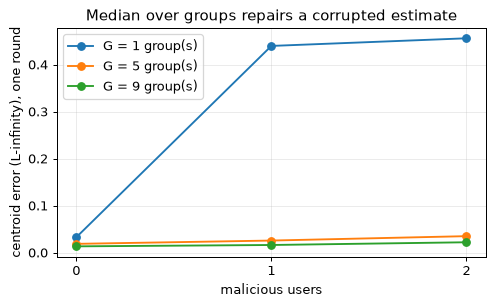

no attack: G=1 error 0.033, G=9 error 0.013 | 2 malicious users: G=1 error 0.456, G=9 error 0.022


In [29]:
# ---- 5. the closing remark of Section V: malicious participants and the median over groups -------------------------------------------
# One round of the protocol from the converged classical centroids. A malicious participant adds a phase offset to every query.
Q_M, SH_M = 6, 10
target = lloyd(X_part, mu_cl, 1)                                    # classical update with all honest users
def grouped_round(X, mu, G, n_mal, r):
    N = len(X); perm = r.permutation(N); groups = np.array_split(perm, G); cents = []
    for g_i, gidx in enumerate(groups):
        off = 0.4 if g_i < n_mal else 0.0      # CHOICE: a malicious user adds a total phase offset of 0.4 to every query of its group
        new, _, _ = quantum_round(X[gidx], mu, Q_M, SH_M, r, malicious_offset=off); cents.append(new)
    return np.median(np.array(cents), axis=0)

rows = []
for G in (1, 5, 9):
    for n_mal in (0, 1, 2):
        errs = [np.abs(grouped_round(X_part, mu_cl, G, n_mal, rk) - target).max() for _ in range(N_TRIALS_KM)]
        q_rot = (1 + D_PART) * rotations_per_estimate(Q_M, SH_M); tv = float(np.sin(min(q_rot / (2 * (N_PART / G)), np.pi / 2)))
        rows.append(dict(groups_G=G, malicious_users=n_mal, centroid_error_Linf=np.mean(errs), group_size=N_PART // G, TV_membership_per_round=tv))
MAL = pd.DataFrame(rows); display(MAL.round(4))
piv = MAL.pivot(index="groups_G", columns="malicious_users", values="centroid_error_Linf")
MAL_G1_2 = float(piv.loc[1, 2]); MAL_G9_2 = float(piv.loc[9, 2]); MAL_G9_0 = float(piv.loc[9, 0]); MAL_G1_0 = float(piv.loc[1, 0])
fig, ax = plt.subplots(figsize=(5.6, 3.5))
for G in (1, 5, 9): ax.plot([0, 1, 2], piv.loc[G].values, "o-", label=f"G = {G} group(s)")
ax.set_xlabel("malicious users"); ax.set_ylabel("centroid error (L-infinity), one round"); ax.set_xticks([0, 1, 2]); ax.set_title("Median over groups repairs a corrupted estimate"); ax.legend(); plt.tight_layout(); plt.show()
print(f"no attack: G=1 error {MAL_G1_0:.3f}, G=9 error {MAL_G9_0:.3f} | 2 malicious users: G=1 error {MAL_G1_2:.3f}, G=9 error {MAL_G9_2:.3f}")

## 11. Paper versus this notebook: a verdict for every claim

The paper reports **no measured numbers**, so the "paper" column states the claim in the paper's own terms and the
"notebook" column the number that was measured here. Verdict rules (they are coded in the next cell):

* **reproduced**: the statement is a theorem or bound and it holds in every case tried, or an empirical statement is met within
  the repository tolerance (2 accuracy points / 0.02);
* **not reached**: the statement is empirical or quantitative and the notebook measured something else (the gap is shown);
* **cannot be checked**: the statement concerns query complexity in an oracle model, quantum speedups or hardware that a
  classical simulator cannot test (a bound whose certified radius is below one compromised member is also reported this way,
  because it cannot be tested);
* **own check**: something we derived ourselves (it is not a claim of the paper); it is reported separately.

In [30]:
V = []
def verdict(cid, claim, paper, nb, status, note=""): V.append(dict(id=cid, claim=claim, paper=paper, notebook=nb, verdict=status, note=note))

verdict("C1", "Lemma 3: unit-vector embedding", "<x^dag_j|x_k> = <x_j,x_k>/R^2, dimension N(2Nv+1)",
        f"max error {LEMMA3_ERR:.1e}", "reproduced" if LEMMA3_ERR < 1e-10 else "not reached")
verdict("C2", "Lemma 4: median is stable", "|median(P) - median(Q)| <= alpha L; the mean is not stable",
        f"holds in {len(L4)} of {len(L4)} cases; mean shift is {L4['mean shift / median shift'].median():.0f}x the median shift (median over cases)",
        "reproduced" if LEMMA4_HOLDS else "not reached", "L estimated from the data on [1/2-alpha, 1/2+alpha]")
verdict("C3", "Theorem 5(2): robust PCA matrix", "||M - M'||_2 <= 5 alpha L (d+2)",
        f"holds for every alpha and attack; largest shift/bound = {THM5_RATIO:.3f}", "reproduced" if THM5_HOLDS else "not reached", "bound is loose")
verdict("C4", "Robust PCA helps against PCA poisoning (motivation of Section III)", "median matrix makes the detector secure",
        f"spam-mimicry poisoning at alpha={max(DET_ALPHAS)}: AUC standard {DET_ATK[0]:.2f} (clean {DET_CLEAN[0]:.2f}) vs robust {DET_ATK[1]:.2f} (clean {DET_CLEAN[1]:.2f}); gain {DET_GAIN:+.2f}",
        "reproduced" if DET_GAIN >= 0.02 else "not reached", "empirical, spam data, absolute AUC under attack")
verdict("C5", "Bootstrap sets exclude a constant fraction", "'with high probability each training set will exclude a constant fraction'",
        f"{100*OOB_FRAC:.1f} % excluded (1/e = 36.8 %)", "reproduced" if abs(OOB_FRAC - 1 / np.e) < 0.02 else "not reached")
gain = BAG_ACC - SINGLE_ACC
verdict("C6", "Bagging makes better classifiers (Section IV)", "ensemble of weak classifiers improves the classifier",
        f"single VQC {100*SINGLE_ACC:.1f} % vs quantum bag {100*BAG_ACC:.1f} % ({100*gain:+.1f} pts); bagged SVC {100*BAGSVC_ACC:.1f} % vs SVC {100*SVC_ACC:.1f} %",
        "reproduced" if gain >= 0.02 else "not reached", "gain below the 2-point tolerance counts as not reached")
verdict("C6b", "Bagging limits the impact of a poisoned fraction of the training set (Section II)", "'limit the impact of an adversary that controls a small fraction of the data set'",
        f"spam-recall drop at eta={eta_max}: single VQC {100*POIS_DROP_SINGLE:.1f} pts vs quantum bag {100*POIS_DROP_BAG:.1f} pts; single SVC {100*POIS_DROP_SVC:.1f} pts vs bagged SVC {100*POIS_DROP_BSVC:.1f} pts",
        "reproduced" if POIS_DROP_BAG <= POIS_DROP_SINGLE - 0.02 else "not reached", "label-flip (false-negative) attack; 2-point tolerance on the drop")
verdict("C7", "Definition 6 is realised by phase estimation", "project onto eigenspaces of C, class = sign of the eigenvalue",
        f"circuit == textbook distribution (<1e-9); top-bit decisions agree with the ideal projector on {100*QPE_AGREE:.1f} % of test e-mails (m={QPE_BITS})",
        "reproduced" if QPE_AGREE >= 0.98 else "not reached")
verdict("C8", "Eq. (8): sign of the mean is fragile", "a single compromised classifier can control the class",
        f"{100*EQ8_FLIP1:.0f} % of correctly classified e-mails flipped by 1 of {N_MEMBERS} members; median {MED_EXP:.0f} members needed",
        "reproduced" if EQ8_FLIP1 > 0 else "not reached")
verdict("C9", "Eigenspace read-out is harder to break than the mean", "compromising one classifier has no substantial impact when the gap is large",
        f"median members needed: sign-of-mean {MED_EXP:.0f}, eigenspace (strongest attack found) {MED_EIG:.0f}, majority vote {MED_MAJ:.0f}",
        "reproduced" if MED_EIG > MED_EXP else "not reached", "empirical; strongest attack found by reflection + hill-climbing, not a proof")
verdict("C10", "Corollary 10: no flip while alpha < gamma/4", "class cannot change",
        f"eigenvalue signs stay unchanged in {SIGN_OK} of {SIGN_N} reflection attacks (the paper's argument holds), but the class was flipped with a/M < gamma/4 "
        f"for {100*COR10_FLIPPED:.0f} % of {len(ATT)} attacked e-mails (certificate covers >= 1 member for {100*CERT_NONVAC:.0f} %, median {ATT.a_cert.median():.0f} of {N_MEMBERS})",
        "cannot be checked" if CERT_NONVAC == 0 else ("reproduced" if COR10_VIOL == 0 else "not reached"),
        "vacuous when the certified radius is below one member; otherwise the conclusion does not follow because the eigenvectors rotate")
verdict("C10b", "OWN: margin-aware repair of Corollary 10", "(not in the paper) no flip while alpha < m g/(1+2m)",
        f"violated for {CERT2_VIOL} of {len(ATT)} attacked e-mails; certifies >= 1 member for {100*CERT2_NONVAC:.0f} %",
        "own check passed" if CERT2_VIOL == 0 else "own check failed", "derived in section 7; checked numerically only")
verdict("C11", "Eq. (10) and (A32): perturbation bounds", "||C'-C|| <= 2 alpha; eigenvalue shift <= 2 alpha",
        f"max ratios {EQ10_RATIO:.3f} and {A32_RATIO:.3f} (must be <= 1)", "reproduced" if max(EQ10_RATIO, A32_RATIO) <= 1 + 1e-9 else "not reached")
verdict("C12", "Lemma 8: Taylor-series cost", "calls O(t log(t/eps)/loglog(t/eps)), independent of M",
        f"r*K / paper expression varies by {ratio_spread:.2f}x over 16 (t, eps) settings; K identical for M = 3, 7, {N_MEMBERS}: {K_by_M}",
        "reproduced" if ratio_spread < 3 and len(set(K_by_M.values())) <= 2 else "not reached", "scaling of the mathematics only")
verdict("C13", "Theorem 5(1), Theorem 9, 'exponential speedup', 'quadratically easier' bagging", "query-complexity advantages in an oracle (QRAM) model",
        "not testable on a classical simulator; the oracle cost model is not implemented", "cannot be checked")
verdict("C14", "Lemma 11: O(1/eps) rotations suffice", "error eps with O(1/eps) rotations per user",
        f"log-log slope of error vs rotations = {LEM11_SLOPE:.2f} (-1 expected)", "reproduced" if -1.25 <= LEM11_SLOPE <= -0.75 else "not reached")
verdict("C15", "Theorem 12: eavesdropper's best success", "1/2 + O(q/N)",
        f"Circuit 4 and Monte-Carlo agree with 1/2 + (1/2) sin(q/2N) <= 1/2 + q/(4N); GHZ probe optimal in a 4-qubit search: {GHZ_OPTIMAL}",
        "reproduced" if (T12_MC_OK and T12_BOUND_OK and GHZ_OPTIMAL) else "not reached")
n_ok = N_PART >= PRIV_N_NEEDED
verdict("C16", "Private k-means is private for N in Omega(R d k /(eps delta))", "advantage delta for N large enough",
        f"with R={KMEANS_ROUNDS} rounds the protocol needs N >= {PRIV_N_NEEDED} users for a 5 % advantage at Q=5, 5 shots; real e-mails available: {N_PART}",
        "reproduced" if n_ok else "not reached", "scaling is right; the constants make N large")
verdict("C17", "Quantum protocol is more accurate than a classical private baseline at equal privacy", "(implied, not stated)",
        f"smaller centroid error than Laplace local DP at the same membership advantage in {QV_WINS} of {QV_TOT} settings with 0.1 <= TV < 1 (N = {N_PART})",
        "reproduced" if (QV_TOT > 0 and QV_WINS == QV_TOT) else "not reached", "own comparison, ideal noiseless quantum protocol")
verdict("C18", "One malicious user breaks the protocol; a median over groups repairs it", "'private but not secure'; median of group centroids mitigates",
        f"2 malicious users: error {MAL_G1_2:.2f} with G=1 vs {MAL_G9_2:.2f} with G=9 (clean G=9: {MAL_G9_0:.2f})",
        "reproduced" if (MAL_G1_2 > 0.1 and MAL_G9_2 < 0.5 * MAL_G1_2) else "not reached")
VT = pd.DataFrame(V)
import textwrap
for r_ in V:
    print(f"[{r_['verdict'].upper()}]  {r_['id']}: {r_['claim']}")
    print(textwrap.fill("paper:    " + r_["paper"], 118, initial_indent="    ", subsequent_indent="              "))
    print(textwrap.fill("notebook: " + r_["notebook"] + (f"   ({r_['note']})" if r_["note"] else ""), 118, initial_indent="    ", subsequent_indent="              "))
print("\nverdict counts:", VT.verdict.value_counts().to_dict())
VERDICT_COUNTS = VT.verdict.value_counts().to_dict()

[REPRODUCED]  C1: Lemma 3: unit-vector embedding
    paper:    <x^dag_j|x_k> = <x_j,x_k>/R^2, dimension N(2Nv+1)
    notebook: max error 2.8e-17
[REPRODUCED]  C2: Lemma 4: median is stable
    paper:    |median(P) - median(Q)| <= alpha L; the mean is not stable
    notebook: holds in 36 of 36 cases; mean shift is 456x the median shift (median over cases)   (L estimated from the
              data on [1/2-alpha, 1/2+alpha])
[REPRODUCED]  C3: Theorem 5(2): robust PCA matrix
    paper:    ||M - M'||_2 <= 5 alpha L (d+2)
    notebook: holds for every alpha and attack; largest shift/bound = 0.042   (bound is loose)
[NOT REACHED]  C4: Robust PCA helps against PCA poisoning (motivation of Section III)
    paper:    median matrix makes the detector secure
    notebook: spam-mimicry poisoning at alpha=0.3: AUC standard 0.68 (clean 0.86) vs robust 0.34 (clean 0.54); gain
              -0.34   (empirical, spam data, absolute AUC under attack)
[REPRODUCED]  C5: Bootstrap sets exclude a constant fr

## 12. Reading the paper critically

*(Written after the executed full run; the numbers quoted are the ones printed above. They change slightly with `FAST_MODE`.)*

**1. The paper proves, it does not measure, and one of its proofs has a gap.** Every theorem about estimation and about the
protocol that we could test holds: Lemma 3, 4, 8 and 11, Theorem 5 (2), Theorem 12, Eq. (10), (A32). Corollary 10 does not. Its
proof is right that no eigenvalue of the ensemble operator C changes sign while alpha < gamma/4 (we confirm it in 1650 of 1650
attacks), but the class is not the sign pattern of the eigenvalues. It is the weight of the test state in the positive
eigenspace, and that eigenspace rotates under a perturbation. The strongest attack we found flips the class at a/M < gamma/4 for
149 of 150 e-mails (median 6 compromised members of 31, against a certified radius of 11). The statement is only true for test
states that are (nearly) eigenvectors of C, which is the case the paper's Eq. (7) discusses. A margin-aware repair (section 7)
holds in all 150 cases and certifies at least one compromised member for 82 % of the e-mails (median 2 of 31), so a bounded
guarantee exists, but it depends on how confident the ensemble already is, not only on the spectral gap.

**2. The projection read-out is not better than the sign of the mean in practice, and both lose to classical majority voting.**
Eq. (8) is reproduced: one compromised member flips 10 % of the correctly classified e-mails under the sign of the mean. But the
eigenspace read-out (Definition 6) flips for 8.7 % of them with one member and needs a median of 6 members against 6 for the
mean, while an ordinary majority vote of hard labels needs a median of 16 and flips none with one member. Majority voting needs
no quantum computer and has an exact certificate. The comparison that matters for the paper's claim is with that classical
baseline, and the notebook's answer is that the quantum read-out gives no robustness gain on this data.

**3. Bagging is not a defence against poisoned training data here.** Section 8 flips a fraction eta of the spam labels. The
bagged VQC loses 66.0 points of spam recall at eta = 0.4 and the single VQC 66.1; the SVCs lose about 35. A bootstrap sample still
contains 63 % of the poisoned points, so every member learns the same lie. The one clean gain of bagging in this notebook (accuracy,
87.3 % to 88.2 %) is below the 2-point tolerance and within the spread of repeated runs.

**4. Robust PCA via medians is stable but not useful on sparse features.** Definition 1 takes the median of a product of two
centred coordinates. Most Spambase word frequencies are exactly zero for most e-mails, so many of those medians are zero and the
matrix carries little information: the clean detector has AUC 0.54 against 0.86 for ordinary PCA, and its AUC moves between 0.34
and 0.54 across attacks, i.e. it never carries a reliable signal. Lemma 4 and Theorem 5 (2) are true, but stability of an estimate
is not accuracy of the detector built on it.

**5. The privacy theorem is honest about its scaling, and the scaling is demanding.** Theorem 12 gives 1/2 + (1/2) sin(q/2N). The
rotations q a user must make for a given accuracy grow like the inverse of the accuracy (Lemma 11), per round and per coordinate.
With three rounds, four coordinates and a centroid error of about 0.1, the protocol needs about 23,000 users for a 5 %
membership advantage; the 2,947 real e-mails available give an advantage of 0.71 for that setting and three of the eight tested
settings leak completely. At equal advantage the quantum protocol is far more accurate than Laplace local differential privacy
(3 of 3 settings with advantage between 0.1 and 1), which is the real attraction of the idea. The analysis assumes an ideal
N-party entangled state, noiseless rotations and honest participants; one malicious user raises the centroid error from 0.03 to
0.44, and a median over nine groups brings it back to 0.02 at the price of a nine-fold smaller group size (hence larger advantage).

**6. What this notebook cannot say.** The speedup claims (exponential for robust PCA, "quadratically easier" bagging) are statements
about query complexity with a QRAM and oracle access to trained classifiers. A classical simulator can verify the mathematics
(Lemma 8: calls grow like t log(t/eps)/loglog(t/eps) and do not depend on M) but not that cost model, so those claims are marked
"cannot be checked". The member classifiers are also small by construction (4 qubits, 12 parameters, one data encoding); a
different encoding or a deeper ansatz may change the spectrum of C and with it the numbers in section 7.

## 13. Exercises

1. **Better members.** Replace the product-state encoding by `zz_feature_map` and the ansatz by `efficient_su2`. Does the
   bag still beat a single VQC? Does the spectral gap gamma of C change, and with it the Corollary 10 radius?
2. **Attack the weights.** The paper allows non-uniform b_j. Let the adversary control the members with the largest b_j
   and show how the minimum number of compromised members changes; why does the paper say "the adversary can replace the
   most significant classifier"?
3. **Certified bagging.** For the majority vote, prove that the class cannot change while a < (k_correct - M/2). Add this
   certificate to the table of section 7 and compare it with the Corollary 10 radius for the same e-mails.
4. **Smaller Q, larger N.** In section 10, plot the eavesdropper's advantage against N for fixed (Q, shots) by sub-sampling
   the users. Where does the quantum protocol cross the Laplace baseline?
5. **Non-uniform noise.** Add depolarising noise to circuit 2 (use `qiskit_aer` or density matrices) and measure how many
   evaluation qubits m are still useful. How does this change the read-out accuracy of section 6?